## Kaggle Setup

This notebook is configured to run on **Kaggle with T4 x 2 GPUs**.

**Prerequisites**

1. Upload `COVA-X_Dataset.zip` as a Kaggle dataset (e.g. slug `cova-x-dataset`).
   Kaggle auto-extracts uploaded zips, so the input usually appears as
   `/kaggle/input/<slug>/bank/*.json`, ... - the loader below handles both the
   extracted layout and a raw `.zip` sitting in the input.
2. Add the dataset to this notebook via **Add Data -> Your Datasets**.
3. **Settings -> Accelerator -> GPU T4 x 2**.
4. **Settings -> Internet -> On** (required to download the HuggingFace tokenizers/models
   in section 3.3 and section 7). Without internet, sections 3.3 and 7 cannot run.

**Runtime budget.** Kaggle kills a session at 12 h. Section 7 is the only long part;
`MAX_HOURS_*` in cell 7.0 stops training gracefully and keeps the best checkpoint if
the budget is reached, so a long run ends with a result rather than a dead session.

**Two preflights guard the expensive work.** §0.1 exercises every scikit-learn / scipy /
pandas / XGBoost call against this image's actual library versions in a few seconds. §7.0
trains both transformers for one epoch on ~120 conversations, through the same code path as
the real run, before section 7 commits hours. Either one fails loudly, naming the failing
call, rather than letting the notebook die deep into a long run.


In [5]:
# -- Kaggle paths -----------------------------------------------------
# Kaggle mounts added datasets read-only under /kaggle/input/. The exact depth varies:
# it may be /kaggle/input/<slug>/... or /kaggle/input/datasets/<owner>/<slug>/...
# Nothing below assumes a fixed depth. Writable output goes to /kaggle/working/.

import os, glob

os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')   # silences fork warnings from DataLoader workers

INPUT_DIR     = '/kaggle/input'
WORK_DIR      = '/kaggle/working'
EXTRACT_DIR   = os.path.join(WORK_DIR, 'covax_data')       # used only if the input is a raw .zip
ARTIFACTS_DIR = os.path.join(WORK_DIR, 'covax_artifacts')
os.makedirs(ARTIFACTS_DIR, exist_ok=True)


def show_tree(root, max_depth=5, max_entries=12):
    """Print the shape of the input mount - the first thing to look at when a path fails."""
    if not os.path.isdir(root):
        print('  %s does not exist' % root); return
    base = root.rstrip(os.sep).count(os.sep)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = dirpath.count(os.sep) - base
        if depth >= max_depth:
            dirnames[:] = []
            continue
        dirnames.sort()
        n_json = sum(1 for f in filenames if f.endswith('.json'))
        print('  %s%s/%s' % ('    ' * depth, os.path.basename(dirpath) or root,
                             '   [%d .json]' % n_json if n_json else ''))
        if len(dirnames) > max_entries:
            print('  %s... %d more directories' % ('    ' * (depth + 1), len(dirnames) - max_entries))
            dirnames[:] = dirnames[:max_entries]


# A raw .zip in the input is optional: Kaggle normally extracts dataset zips for you.
zip_candidates = []
if os.path.isdir(INPUT_DIR):
    zip_candidates = sorted(glob.glob(os.path.join(INPUT_DIR, '**', 'COVA-X_Dataset.zip'), recursive=True))
    if not zip_candidates:
        zip_candidates = sorted(glob.glob(os.path.join(INPUT_DIR, '**', '*.zip'), recursive=True))
    print('Input mount layout:')
    show_tree(INPUT_DIR)
else:
    print('Input dir  :', INPUT_DIR, '(does not exist - add the dataset via "Add Data")')

print('\nZip files  :', zip_candidates if zip_candidates else '(none - dataset is probably already extracted)')
print('Artifacts  :', ARTIFACTS_DIR)


Input mount layout:
  input/
      datasets/
          nakibulislamkhan/
              cova-x-dataset/
                  bank/   [1360 .json]
                  government_impersonation/   [1545 .json]
                  grandparent/   [1376 .json]
                  investment/   [975 .json]
                  lottery/   [975 .json]
                  medicare/   [1490 .json]
                  romance/   [1934 .json]
                  virtual_kidnapping/   [1330 .json]

Zip files  : (none - dataset is probably already extracted)
Artifacts  : /kaggle/working/covax_artifacts


In [6]:
# Dependencies. Kaggle's image already ships torch, transformers, accelerate,
# safetensors and xgboost; blindly re-installing them can pull an incompatible
# combination and force a kernel restart. So: install only what is genuinely missing.
import importlib, importlib.util, subprocess, sys

REQUIRED = ['xgboost', 'transformers', 'accelerate', 'safetensors']
missing  = [p for p in REQUIRED if importlib.util.find_spec(p) is None]

if missing:
    print('installing missing packages:', missing)
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-2000:]); print(r.stderr[-2000:])
        raise RuntimeError('pip install failed. Turn Internet ON in Settings, then re-run this cell.')
    print('installed.')
else:
    print('all required packages already present - nothing to install')

print('\nversions')
for m in ['torch', 'transformers', 'xgboost', 'sklearn', 'scipy', 'pandas', 'numpy']:
    try:
        print('  %-14s %s' % (m, getattr(importlib.import_module(m), '__version__', '?')))
    except Exception as e:
        print('  %-14s MISSING (%s)' % (m, e))


all required packages already present - nothing to install

versions
  torch          2.10.0+cu128
  transformers   5.0.0
  xgboost        3.2.0
  sklearn        1.6.1
  scipy          1.16.3
  pandas         2.3.3
  numpy          2.0.2


In [7]:
# Verify GPU availability - expect 2x Tesla T4
import torch

n_gpu = torch.cuda.device_count()
print('PyTorch  :', torch.__version__)
print('CUDA     :', torch.cuda.is_available(), '| build', torch.version.cuda)
print('GPU count:', n_gpu)
for i in range(n_gpu):
    p = torch.cuda.get_device_properties(i)          # NB: .total_memory, not .total_mem
    print('  GPU %d: %-22s %.1f GB' % (i, p.name, p.total_memory / 1024**3))

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if n_gpu == 0:
    print('\n  No GPU. Settings -> Accelerator -> GPU T4 x2. Sections 1-6 still run; section 7 is skipped.')
elif n_gpu == 1:
    print('\n  Only 1 GPU visible. Section 7 will run single-GPU (slower, same results).')


PyTorch  : 2.10.0+cu128
CUDA     : True | build 12.8
GPU count: 2
  GPU 0: Tesla T4               14.6 GB
  GPU 1: Tesla T4               14.6 GB


## 0.1 Preflight — API compatibility check

Runs in a few seconds against the **real** libraries in this Kaggle image, exercising every
scikit-learn / scipy / pandas / XGBoost call the rest of the notebook makes. A version
incompatibility surfaces here with the exact failing call named, instead of ten minutes into
a TF-IDF fit or two hours into section 7.

Nothing below depends on the corpus, so it is safe to run before the dataset is located.


In [8]:
# ---- §0.1 preflight: exercise every third-party API this notebook depends on ----
import numpy as np, warnings, tempfile, os, traceback

# Single source of truth for the XGBoost configuration used in §5, §6 and §9.
# NB: num_class is deliberately absent - the sklearn wrapper derives it from y, and
# passing it as well is redundant (and warns or errors depending on the version).
XGB_BASE = dict(objective='multi:softprob', tree_method='hist',
                n_jobs=-1, eval_metric='mlogloss', random_state=42)

_checks, _failures = [], []

def _check(name, fn):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            detail = fn()
        _checks.append((name, detail or 'ok'))
    except Exception as e:
        _failures.append((name, '%s: %s' % (type(e).__name__, e), traceback.format_exc()))

rng = np.random.default_rng(0)
Y3  = np.repeat([0, 1, 2], 40)                    # 120 rows, all three classes
TXT = ['%s scam call turn about %s' % (a, b)
       for a, b in zip(rng.choice(['bank', 'lottery', 'romance'], 120),
                       rng.choice(['card', 'code', 'wire', 'gift'], 120))]

def _sklearn_vectoriser():
    from sklearn.feature_extraction.text import TfidfVectorizer
    v = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True)
    X = v.fit_transform(TXT)
    assert X.shape[0] == 120
    globals()['_PF_X'] = X
    return 'TfidfVectorizer -> %s' % (X.shape,)

def _sklearn_split():
    from sklearn.model_selection import train_test_split
    strat = np.array(['%s|%d' % (a, b) for a, b in zip(rng.choice(list('AB'), 120), Y3)])
    a, b = train_test_split(np.arange(120), test_size=0.2, random_state=42, stratify=strat)
    return 'train_test_split(stratify=) -> %d/%d' % (len(a), len(b))

def _sklearn_metrics():
    from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                                 classification_report, log_loss, roc_auc_score)
    pred = rng.integers(0, 3, 120)
    assert f1_score(Y3, pred, average=None).shape == (3,)
    f1_score(Y3, pred, average='macro'); f1_score(Y3, pred, average='weighted')
    accuracy_score(Y3, pred); confusion_matrix(Y3, pred)
    classification_report(Y3, pred, target_names=['complied', 'partial', 'rejected'], digits=4)
    P = rng.dirichlet([1, 1, 1], 120).astype(np.float32)     # float32, as XGBoost returns
    log_loss(Y3, P, labels=[0, 1, 2])
    roc_auc_score((Y3 != 2).astype(float), P[:, 0])
    return 'f1/accuracy/confusion/classification_report/log_loss/roc_auc'

def _sklearn_weights():
    from sklearn.utils.class_weight import compute_sample_weight
    w = compute_sample_weight('balanced', Y3)
    assert w.shape == (120,)
    return 'compute_sample_weight'

def _sklearn_cv_float_labels():
    # §10 passes a FLOAT 0.0/1.0 target to StratifiedKFold + cross_val_predict.
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import cross_val_predict, StratifiedKFold
    harm = (Y3 != 2).astype(float)
    p = cross_val_predict(LogisticRegression(max_iter=2000), _PF_X, harm,
                          cv=StratifiedKFold(5, shuffle=True, random_state=42),
                          method='predict_proba')[:, 1]
    assert p.shape == (120,)
    return 'cross_val_predict(float labels, predict_proba)'

def _xgboost():
    import xgboost
    from xgboost import XGBClassifier
    clf = XGBClassifier(**XGB_BASE, n_estimators=10, max_depth=3, learning_rate=0.3,
                        subsample=0.9, colsample_bytree=0.9)
    from sklearn.utils.class_weight import compute_sample_weight
    clf.fit(_PF_X, Y3, sample_weight=compute_sample_weight('balanced', Y3))
    pred, proba = clf.predict(_PF_X), clf.predict_proba(_PF_X)
    assert proba.shape == (120, 3), proba.shape
    assert np.allclose(proba.sum(1), 1, atol=1e-4), 'predict_proba rows must sum to 1'
    assert set(np.unique(pred)) <= {0, 1, 2}
    assert np.isfinite(np.log(np.clip(proba, 1e-12, 1))).all(), 'log-probs must be finite'
    return 'xgboost %s: fit(sparse, sample_weight) / predict / predict_proba' % xgboost.__version__

def _scipy():
    from scipy.optimize import minimize_scalar, minimize
    from scipy import stats
    z = rng.normal(size=(120, 3))
    minimize_scalar(lambda t: float(np.abs(z / np.exp(t)).mean()), bounds=(-3, 3), method='bounded')
    minimize(lambda th: float(((z * th[:3] + th[3:]) ** 2).mean()),
             np.concatenate([np.ones(3), np.zeros(3)]), method='L-BFGS-B')
    g = [rng.normal(size=5) for _ in range(3)]
    stats.shapiro(np.concatenate(g)); stats.ttest_ind(g[0], g[1])
    stats.f_oneway(*g); stats.kruskal(*g)
    return 'minimize_scalar/minimize/shapiro/ttest_ind/f_oneway/kruskal'

def _pandas():
    # Mirrors §12/§13 exactly: a stimulus frame carrying true_harm, and a disjoint
    # response frame that does NOT - so the merge adds one column and does not suffix it.
    import pandas as pd
    stim = pd.DataFrame({'item_id': [str(i) for i in range(120)],
                         'scam_type': rng.choice(list('AB'), 120),
                         'true_label': Y3, 'true_harm': (Y3 != 2).astype(int)})
    resp = pd.DataFrame({'participant_id': rng.integers(0, 12, 240),
                         'condition': rng.integers(1, 5, 240),
                         'item_id': [str(i % 120) for i in range(240)],
                         'judgement': rng.choice(['partial', 'rejected'], 240),
                         'confidence': rng.uniform(50, 99, 240),
                         'decision_ms': rng.uniform(1e3, 3e4, 240)})
    stim.groupby(['scam_type', 'true_label']).size().unstack(fill_value=0)
    m = resp.merge(stim[['item_id', 'true_harm']], on='item_id')
    assert 'true_harm' in m.columns, 'merge suffixed the joined column'
    m['human_harm'] = (m.judgement != 'rejected').astype(int)
    m['p_harm'] = np.where(m.human_harm == 1, m.confidence / 100.0, 1 - m.confidence / 100.0)
    for _, r in stim.head(3).iterrows():
        _ = r.item_id, r.true_harm, r.scam_type
    for c, g in m.groupby('condition'):
        _ = g.decision_ms.median(), (g.human_harm == g.true_harm).mean()
    per = m.groupby(['participant_id', 'condition']).human_harm.mean().reset_index()
    _ = per[per.condition == 1].human_harm.values
    stim.scam_type.nunique()
    with tempfile.TemporaryDirectory() as d:
        stim.to_csv(os.path.join(d, 't.csv'), index=False)
    return 'pandas %s: groupby/unstack/merge/np.where/iterrows/reset_index/to_csv' % pd.__version__

def _matplotlib():
    import matplotlib
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(4, 2))
    axes[0].bar([0.1, 0.2], [1, 2], width=0.05, edgecolor='black')
    with tempfile.TemporaryDirectory() as d:
        fig.savefig(os.path.join(d, 'f.png'), dpi=50, bbox_inches='tight')
    plt.close(fig)
    return 'matplotlib %s: subplots/bar/savefig' % matplotlib.__version__

for nm, fn in [('sklearn  TfidfVectorizer', _sklearn_vectoriser),
               ('sklearn  train_test_split', _sklearn_split),
               ('sklearn  metrics', _sklearn_metrics),
               ('sklearn  class weights', _sklearn_weights),
               ('sklearn  cross_val_predict', _sklearn_cv_float_labels),
               ('xgboost  classifier', _xgboost),
               ('scipy    optimize + stats', _scipy),
               ('pandas   frame ops', _pandas),
               ('matplotlib figure', _matplotlib)]:
    _check(nm, fn)

print('PREFLIGHT - third-party API compatibility')
print('=' * 78)
for nm, detail in _checks:
    print('  PASS  %-26s %s' % (nm, detail))
for nm, msg, tb in _failures:
    print('  FAIL  %-26s %s' % (nm, msg))

if _failures:
    print('\n' + '=' * 78)
    print(_failures[0][2])
    raise RuntimeError('%d preflight check(s) failed - see the traceback above. The rest of '
                       'the notebook uses these same calls and would fail later.' % len(_failures))
print('\n  %d/%d checks passed - the CPU half of the notebook is API-compatible with this image.'
      % (len(_checks), len(_checks) + len(_failures)))


PREFLIGHT - third-party API compatibility
  PASS  sklearn  TfidfVectorizer   TfidfVectorizer -> (120, 21)
  PASS  sklearn  train_test_split  train_test_split(stratify=) -> 96/24
  PASS  sklearn  metrics           f1/accuracy/confusion/classification_report/log_loss/roc_auc
  PASS  sklearn  class weights     compute_sample_weight
  PASS  sklearn  cross_val_predict cross_val_predict(float labels, predict_proba)
  PASS  xgboost  classifier        xgboost 3.2.0: fit(sparse, sample_weight) / predict / predict_proba
  PASS  scipy    optimize + stats  minimize_scalar/minimize/shapiro/ttest_ind/f_oneway/kruskal
  PASS  pandas   frame ops         pandas 2.3.3: groupby/unstack/merge/np.where/iterrows/reset_index/to_csv
  PASS  matplotlib figure          matplotlib 3.10.0: subplots/bar/savefig

  9/9 checks passed - the CPU half of the notebook is API-compatible with this image.


# Reproducing the COVA-X Published Baselines

Reproduction of **Lochstampfor & Roy (2026), arXiv:2606.06879v1** — _An Expanded Synthetic Conversation
Dataset for Multi-Turn Smishing Detection_ — on the distributed COVA-X v1.1 artifact.

**Kaggle edition** — configured for T4 × 2 GPU with DataParallel.

**What this notebook does**

1. Reconstructs the published task exactly: 3-class outcome collapse, stratified 80/10/10, seed 42.
2. Verifies the paper's descriptive claims against the released corpus (§2–3).
3. Reproduces the **XGBoost + TF-IDF** baseline and reports the gap (§5).
4. Runs the **text-view ablation** that separates _observing_ an outcome from _predicting_ it (§6).
5. Optionally trains **DistilBERT v2 (tail-512)** and **Longformer (1024)** if a GPU is present (§7).

**Reference values (paper, Table V — COVA-X test set, n=1,099)**

| Model                                   | Acc.   | F1-macro | F1-weighted |
| --------------------------------------- | ------ | -------- | ----------- |
| Longformer (full, 1024)                 | 0.7971 | 0.7786   | 0.7956      |
| XGBoost + TF-IDF (+28 engineered feats) | 0.7843 | 0.7563   | 0.7825      |
| DistilBERT v2 (tail-512)                | 0.7753 | 0.7632   | 0.7730      |

**Headline outcome of this reproduction:** the _protocol_ reproduces exactly; the XGBoost _result_ does
not, and cannot — the 28 engineered features are cited but never enumerated. Three descriptive claims
in the paper are not supported by the released artifact. Details in §8.


## 0. Setup — extract the corpus

**On Kaggle:** your uploaded dataset is read-only under `/kaggle/input/`. This cell
extracts the zip to `/kaggle/working/covax_data` (writable).


In [9]:
import os, sys, glob, json, pickle, collections, warnings, zipfile
warnings.filterwarnings('ignore')
import numpy as np

# ------------------------------------------------------------------ CONFIGURE
# The corpus is a directory holding one sub-directory per scam type: bank/, romance/, ...
MIN_FILES = 1000                                   # a plausible corpus, not merely ">=1 json"
MAX_DEPTH = 10                                     # Kaggle nests mounts differently per account
ZIP_PATH  = zip_candidates[0] if zip_candidates else None
# -----------------------------------------------------------------------------

def _ok(p):
    return bool(p) and os.path.isdir(p) and len(glob.glob(os.path.join(p, '*', '*.json'))) >= MIN_FILES

def _find_corpus(root, max_depth=MAX_DEPTH):
    """Locate the directory whose immediate sub-directories hold the corpus JSON files.

    Depth-agnostic on purpose. Kaggle mounts a dataset at /kaggle/input/<slug>/ on some
    accounts and /kaggle/input/datasets/<owner>/<slug>/ on others, and a zip may add one
    more level; a hard-coded search depth breaks on whichever layout it was not written for.
    Strategy: count .json files per directory, then take the parent with the most of them
    that actually looks like the corpus.
    """
    if not root or not os.path.isdir(root):
        return None
    if _ok(root):
        return root
    base = root.rstrip(os.sep).count(os.sep)
    tally = collections.Counter()
    for dirpath, dirnames, filenames in os.walk(root):
        if dirpath.count(os.sep) - base >= max_depth:
            dirnames[:] = []                       # do not descend further
            continue
        n = sum(1 for f in filenames if f.endswith('.json'))
        if n:
            tally[os.path.dirname(dirpath)] += n
    for cand, n in tally.most_common():
        if n >= MIN_FILES and _ok(cand):
            return cand
    return None

DATA_DIR = _find_corpus(EXTRACT_DIR) or _find_corpus(INPUT_DIR)

if DATA_DIR is None and ZIP_PATH:
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    print('Extracting', ZIP_PATH, '->', EXTRACT_DIR)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(EXTRACT_DIR)                 # handles both flat and single-root zips
    DATA_DIR = _find_corpus(EXTRACT_DIR)

if DATA_DIR is None:
    print('Searched this tree and found no directory holding >= %d corpus files:' % MIN_FILES)
    show_tree(INPUT_DIR, max_depth=6)
    raise FileNotFoundError(
        'COVA-X corpus not found.\n'
        '  Expected a directory containing bank/, romance/, ... each holding *.json,\n'
        '  anywhere under /kaggle/input/ (any depth) or as COVA-X_Dataset.zip in the input.\n'
        '  If the tree printed above shows the data, set DATA_DIR by hand in this cell.\n'
        '  Otherwise add the dataset via "Add Data -> Your Datasets" and re-run.')

print('DATA_DIR:', os.path.abspath(DATA_DIR))
print('types   :', sorted(d for d in os.listdir(DATA_DIR)
                          if os.path.isdir(os.path.join(DATA_DIR, d))))
print('files   :', len(glob.glob(os.path.join(DATA_DIR, '*', '*.json'))))


DATA_DIR: /kaggle/input/datasets/nakibulislamkhan/cova-x-dataset
types   : ['bank', 'government_impersonation', 'grandparent', 'investment', 'lottery', 'medicare', 'romance', 'virtual_kidnapping']
files   : 10985


## 1. Load the corpus and apply the paper's 3-class collapse

Per §V-A2: _complied_ = `successful_scam`; _partial_ = `partial_compliance`; _rejected_ =
`verification_attempt` + `scam_detected` + `quick_rejection`.


In [10]:
CACHE = os.path.join(ARTIFACTS_DIR, 'covax_cache.pkl')
paths = sorted(glob.glob(os.path.join(DATA_DIR, '*', '*.json')))

convs = None
if os.path.exists(CACHE):
    try:
        with open(CACHE, 'rb') as fh:
            convs = pickle.load(fh)
        if not isinstance(convs, list) or len(convs) != len(paths):
            print('cache is stale (%s entries vs %d files) - rebuilding'
                  % (len(convs) if isinstance(convs, list) else '?', len(paths)))
            convs = None
    except Exception as e:
        print('cache unreadable (%s) - rebuilding' % e)
        convs = None

if convs is None:
    convs = []
    for p in paths:
        with open(p, encoding='utf-8') as fh:
            d = json.load(fh)
        v = d.get('victim_config') or {}
        convs.append({'cid': d.get('conversation_id'), 'scam_type': d.get('scam_type'),
                      'outcome': d.get('outcome'), 'legacy': d.get('legacy_contamination'),
                      'n_turns': len(d.get('turns', [])),
                      'awareness': v.get('scam_awareness'), 'trust': v.get('trust_level'),
                      'turns': [(t.get('role'), t.get('content', '')) for t in d.get('turns', [])]})
    with open(CACHE, 'wb') as fh:
        pickle.dump(convs, fh, protocol=4)

C3    = {'successful_scam': 0, 'partial_compliance': 1,
         'verification_attempt': 2, 'scam_detected': 2, 'quick_rejection': 2}
NAMES = ['complied', 'partial', 'rejected']

unknown = sorted({d['outcome'] for d in convs} - set(C3))
if unknown:
    raise ValueError('unmapped outcome label(s) in the corpus: %s - extend C3 before continuing' % unknown)

y  = np.array([C3[d['outcome']] for d in convs])
st = np.array([d['scam_type'] for d in convs])

print('corpus: %d conversations\n' % len(convs))
for k, n in enumerate(NAMES):
    print('  %-9s %5d  (%.1f%%)' % (n, (y == k).sum(), 100 * (y == k).mean()))


corpus: 10985 conversations

  complied   1671  (15.2%)
  partial    4279  (39.0%)
  rejected   5035  (45.8%)


## 2. Verification — does Table I reproduce?

Paper Table I gives outcome counts per scam type across all five terminal states. If all 40 cells match,
the released artifact is the one the paper describes.


In [11]:
PAPER_T1 = {  # succ, part, ver, det, rej
 "romance":(254,921,481,267,11), "government_impersonation":(202,468,551,294,30),
 "medicare":(254,376,268,159,433), "virtual_kidnapping":(443,659,110,107,11),
 "grandparent":(63,296,868,144,5), "bank":(173,377,569,29,212),
 "lottery":(196,477,290,10,2), "investment":(86,705,146,5,33)}
ORD = ["successful_scam","partial_compliance","verification_attempt","scam_detected","quick_rejection"]

allok = True
print("  %-26s %-26s %-26s" % ("scam type", "paper Table I", "released corpus"))
for stype, exp in PAPER_T1.items():
    got = tuple(sum(1 for d in convs if d["scam_type"] == stype and d["outcome"] == o) for o in ORD)
    ok = (got == exp); allok &= ok
    print("  %-26s %-26s %-26s %s" % (stype, exp, got, "match" if ok else "*** DIFFERS ***"))
print("\n  all 40 cells reproduce:", allok)

  scam type                  paper Table I              released corpus           
  romance                    (254, 921, 481, 267, 11)   (254, 921, 481, 267, 11)   match
  government_impersonation   (202, 468, 551, 294, 30)   (202, 468, 551, 294, 30)   match
  medicare                   (254, 376, 268, 159, 433)  (254, 376, 268, 159, 433)  match
  virtual_kidnapping         (443, 659, 110, 107, 11)   (443, 659, 110, 107, 11)   match
  grandparent                (63, 296, 868, 144, 5)     (63, 296, 868, 144, 5)     match
  bank                       (173, 377, 569, 29, 212)   (173, 377, 569, 29, 212)   match
  lottery                    (196, 477, 290, 10, 2)     (196, 477, 290, 10, 2)     match
  investment                 (86, 705, 146, 5, 33)      (86, 705, 146, 5, 33)      match

  all 40 cells reproduce: True


## 3. Verification — three claims the released artifact does not support

Each is checked against the paper's own words. These are recorded as documentation findings, **not** as
challenges to the headline result (see §8).


In [12]:
print("=== 3.1  Minimum-turn floor  (paper III-A: 'Conversations under 10 turns were discarded') ===")
short = [d for d in convs if d["n_turns"] < 10]
print("  released conversations with <10 turns : %d  (%.1f%%)" % (len(short), 100*len(short)/len(convs)))
print("  minimum turn count observed           : %d" % min(d["n_turns"] for d in convs))
print("  by outcome:", dict(collections.Counter(d["outcome"] for d in short).most_common()))

print("\n=== 3.2  Legacy contamination  (paper IV-C / VI-E) ===")
PAPER_LEG = {"government_impersonation": 357, "medicare": 348, "virtual_kidnapping": 355}
SHEET_LEG = {"government_impersonation": 322, "medicare": 315, "virtual_kidnapping": 0}
print("  %-26s %8s %12s %9s" % ("scam type", "paper", "data sheet", "corpus"))
for k in PAPER_LEG:
    got = sum(1 for d in convs if d["scam_type"] == k and d["legacy"])
    print("  %-26s %8d %12d %9d" % (k, PAPER_LEG[k], SHEET_LEG[k], got))
print("  corpus total flagged: %d   (data sheet: 637)" % sum(1 for d in convs if d["legacy"]))
print("  note: the data sheet documents a VK regeneration, which explains the third row.")

=== 3.1  Minimum-turn floor  (paper III-A: 'Conversations under 10 turns were discarded') ===
  released conversations with <10 turns : 631  (5.7%)
  minimum turn count observed           : 2
  by outcome: {'scam_detected': 184, 'partial_compliance': 181, 'verification_attempt': 163, 'quick_rejection': 88, 'successful_scam': 15}

=== 3.2  Legacy contamination  (paper IV-C / VI-E) ===
  scam type                     paper   data sheet    corpus
  government_impersonation        357          322       322
  medicare                        348          315       315
  virtual_kidnapping              355            0         0
  corpus total flagged: 637   (data sheet: 637)
  note: the data sheet documents a VK regeneration, which explains the third row.


### 3.3 Token lengths — the consequential one

§VI-B is the paper's _explanation_ for its headline result: Longformer wins through "full-context
encoding without truncation," citing _"maximum observed token count: 874, well within the 1,024-token
training limit."_

This cell measures the released corpus with the actual `distilbert-base-uncased` WordPiece tokenizer.


In [13]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained('distilbert-base-uncased')

def tok_lengths(strings, add_special, chunk=256):
    """Batched so a 10,985-document / 150,000-turn pass does not spike RAM,
    and verbose=False so the 'sequence longer than 512' notice is not printed 10,985 times."""
    out = []
    for i in range(0, len(strings), chunk):
        enc = tok(strings[i:i + chunk], add_special_tokens=add_special,
                  truncation=False, verbose=False)['input_ids']
        out.extend(len(x) for x in enc)
    return np.array(out)

conv_text = [' '.join(c for _, c in d['turns']) for d in convs]
L = tok_lengths(conv_text, True)

print('per-CONVERSATION WordPiece tokens (n=%d)' % len(L))
print('  median %d | p95 %d | p99 %d | MAX %d\n' % (np.median(L), np.percentile(L, 95),
                                                    np.percentile(L, 99), L.max()))
print('  %-58s %s' % ('paper claim (VI-B)', 'measured'))
print('  %-58s %d' % ("'maximum observed token count: 874'", L.max()))
print('  %-58s %.1f%%' % ("DistilBERT-512 truncates '~20% of sampled conversations'", 100 * (L > 512).mean()))
print('  %-58s %.1f%%' % ("Longformer-1024 'accommodates all without information loss'",
                          100 * (L > 1024).mean()))

# Test the most plausible innocent reading: was 874 a PER-TURN maximum?
turns = [c for d in convs for _, c in d['turns']]
TL = tok_lengths(turns, False)
print('\n  per-TURN tokens: median %d, max %d  ->  a per-turn reading %s explain 874'
      % (np.median(TL), TL.max(), 'COULD' if 700 < TL.max() < 1100 else 'does NOT'))


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

per-CONVERSATION WordPiece tokens (n=10985)
  median 1221 | p95 2638 | p99 3385 | MAX 18246

  paper claim (VI-B)                                         measured
  'maximum observed token count: 874'                        18246
  DistilBERT-512 truncates '~20% of sampled conversations'   94.5%
  Longformer-1024 'accommodates all without information loss' 61.9%

  per-TURN tokens: median 73, max 1135  ->  a per-turn reading does NOT explain 874


## 4. The published split

§V-A1: stratified train 80% / validation 10% / test 10%, seed 42, preserving the joint distribution of
scam type × outcome class. Target: 8,787 / 1,099 / 1,099.


In [14]:
from sklearn.model_selection import train_test_split

strat = np.array(["%s|%d" % (a, b) for a, b in zip(st, y)])
idx   = np.arange(len(y))
tr, tmp = train_test_split(idx, test_size=0.20, random_state=42, stratify=strat)
va, te  = train_test_split(tmp, test_size=0.50, random_state=42, stratify=strat[tmp])

print("  %-28s %6s %6s %6s" % ("", "train", "val", "test"))
print("  %-28s %6d %6d %6d" % ("paper (V-A1)", 8787, 1099, 1099))
print("  %-28s %6d %6d %6d" % ("this reproduction", len(tr), len(va), len(te)))
print("\n  train class distribution : rejected %.1f%%  partial %.1f%%  complied %.1f%%"
      % (100*(y[tr]==2).mean(), 100*(y[tr]==1).mean(), 100*(y[tr]==0).mean()))
print("  paper (V-A2)             : rejected 46.4%   partial 37.5%   complied 16.1%")
print("\n  test class n : complied %d  partial %d  rejected %d   [paper: 166 / 429 / 504]"
      % ((y[te]==0).sum(), (y[te]==1).sum(), (y[te]==2).sum()))

                                train    val   test
  paper (V-A1)                   8787   1099   1099
  this reproduction              8788   1098   1099

  train class distribution : rejected 45.8%  partial 39.0%  complied 15.2%
  paper (V-A2)             : rejected 46.4%   partial 37.5%   complied 16.1%

  test class n : complied 165  partial 430  rejected 504   [paper: 166 / 429 / 504]


## 5. XGBoost + TF-IDF reproduction

Paper config (Table IV): _"sklearn defaults; TF-IDF unigrams + bigrams, 5,000 max features, sublinear
TF; plus 28 engineered features from the first paper's feature set."_

**The 28 engineered features are not enumerated in the paper**, so they cannot be reproduced. Everything
else is specified precisely and is used verbatim below. Several hyperparameter settings and a balanced
class-weight variant are run to bound what the missing features could account for.


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

full = [' '.join('%s: %s' % (r, c) for r, c in d['turns']) for d in convs]
vec  = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True)
Xtr  = vec.fit_transform([full[j] for j in tr])
Xte  = vec.transform([full[j] for j in te])

# XGB_BASE is defined and exercised in the §0.1 preflight cell. Re-created here only so
# this cell still runs standalone after a kernel restart.
if 'XGB_BASE' not in globals():
    XGB_BASE = dict(objective='multi:softprob', tree_method='hist',
                    n_jobs=-1, eval_metric='mlogloss', random_state=42)

def run_xgb(tag, balanced=False, **kw):
    w = compute_sample_weight('balanced', y[tr]) if balanced else None
    clf = XGBClassifier(**XGB_BASE, **kw)
    clf.fit(Xtr, y[tr], sample_weight=w)
    p = clf.predict(Xte)
    a  = accuracy_score(y[te], p)
    mf = f1_score(y[te], p, average='macro')
    wf = f1_score(y[te], p, average='weighted')
    pc = f1_score(y[te], p, average=None)
    print('  %-42s %.4f  %.4f  %.4f | %s'
          % (tag, a, mf, wf, '  '.join('%.3f' % f for f in pc)), flush=True)
    return a, mf, wf, p

print('  %-42s %6s  %7s  %6s | %s' % ('', 'acc', 'macroF1', 'wtdF1', 'complied/partial/rejected F1'))
print('  %-42s %.4f  %.4f  %.4f | %s'
      % ('>>> PAPER (with 28 engineered feats)', 0.7843, 0.7563, 0.7825, '0.677  0.728  0.864'))
print('  ' + '-' * 100)
run_xgb('xgboost defaults', n_estimators=100, max_depth=6, learning_rate=0.3)
best = run_xgb('n=200 depth=6 lr=0.1 subsample=0.9', n_estimators=200, max_depth=6,
               learning_rate=0.1, subsample=0.9, colsample_bytree=0.9)
run_xgb('n=200 depth=6 lr=0.1 + balanced weights', balanced=True, n_estimators=200, max_depth=6,
        learning_rate=0.1, subsample=0.9, colsample_bytree=0.9)
p_best = best[3]


                                                acc  macroF1   wtdF1 | complied/partial/rejected F1
  >>> PAPER (with 28 engineered feats)       0.7843  0.7563  0.7825 | 0.677  0.728  0.864
  ----------------------------------------------------------------------------------------------------
  xgboost defaults                           0.7152  0.6626  0.7086 | 0.514  0.659  0.815
  n=200 depth=6 lr=0.1 subsample=0.9         0.7361  0.6835  0.7280 | 0.540  0.678  0.832
  n=200 depth=6 lr=0.1 + balanced weights    0.7207  0.6863  0.7170 | 0.597  0.639  0.823


### 5.1 Where the gap sits

The aggregate gap is uninformative on its own; the confusion matrix localises it.


In [16]:
PAPER_CM = [[108, 53, 5], [43, 308, 78], [2, 56, 446]]   # Table VII, XGBoost
cm = confusion_matrix(y[te], p_best)

print("  rows = true class,  columns = predicted\n")
print("  %-10s %-26s %-26s %s" % ("", "this reproduction", "paper (Table VII)", "correct: ours vs paper"))
for k, n in enumerate(NAMES):
    print("  %-10s %-26s %-26s %d vs %d   (%+d)"
          % (n, " ".join("%5d" % c for c in cm[k]), " ".join("%5d" % c for c in PAPER_CM[k]),
             cm[k][k], PAPER_CM[k][k], cm[k][k] - PAPER_CM[k][k]))
print("\n  totals: ours %d/%d = %.4f   paper 862/1099 = 0.7843"
      % (cm.trace(), len(te), cm.trace()/len(te)))
print("\n", classification_report(y[te], p_best, target_names=NAMES, digits=4))

  rows = true class,  columns = predicted

             this reproduction          paper (Table VII)          correct: ours vs paper
  complied      77    68    20            108    53     5          77 vs 108   (-31)
  partial       40   281   109             43   308    78          281 vs 308   (-27)
  rejected       3    50   451              2    56   446          451 vs 446   (+5)

  totals: ours 809/1099 = 0.7361   paper 862/1099 = 0.7843

               precision    recall  f1-score   support

    complied     0.6417    0.4667    0.5404       165
     partial     0.7043    0.6535    0.6779       430
    rejected     0.7776    0.8948    0.8321       504

    accuracy                         0.7361      1099
   macro avg     0.7078    0.6717    0.6835      1099
weighted avg     0.7285    0.7361    0.7280      1099



## 6. Text-view ablation — observing an outcome vs predicting it

This is the analysis the reproduction exists to support. Labels, split, model and vectoriser are held
fixed; **only the visible text changes**.

- **full conversation** — what Longformer sees (nominally)
- **tail 512 words** — the DistilBERT v2 strategy, which the paper describes as _"preserving the
  outcome-critical final turns"_
- **head 512 words** — the same budget from the other end, isolating _position_ from _quantity_
- **first 6 turns** — an early-triage prefix, before the outcome has occurred

If the published task partly depends on the ending being visible, tail should beat head, and both
should beat a short prefix.


In [17]:
def view_full(d): return ' '.join('%s: %s' % (r, c) for r, c in d['turns'])
def view_tail(d, n=512): w = view_full(d).split(); return ' '.join(w[-n:])
def view_head(d, n=512): w = view_full(d).split(); return ' '.join(w[:n])
def view_pre6(d):        return ' '.join('%s: %s' % (r, c) for r, c in d['turns'][:6])

VIEWS = [('full conversation', view_full),
         ('tail 512 words  (DistilBERT v2 view)', view_tail),
         ('head 512 words', view_head),
         ('first 6 turns   (early-triage prefix)', view_pre6)]

print('  %-38s %6s  %7s | %s' % ('text view', 'acc', 'macroF1', 'complied/partial/rejected F1'))
abl = {}
for tag, fn in VIEWS:
    txt = [fn(d) for d in convs]
    v = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, sublinear_tf=True)
    A = v.fit_transform([txt[j] for j in tr]); B = v.transform([txt[j] for j in te])
    clf = XGBClassifier(**XGB_BASE, n_estimators=200, max_depth=6, learning_rate=0.1,
                        subsample=0.9, colsample_bytree=0.9).fit(A, y[tr])
    p = clf.predict(B)
    a = accuracy_score(y[te], p); m = f1_score(y[te], p, average='macro')
    pc = f1_score(y[te], p, average=None); abl[tag] = (a, m, pc)
    print('  %-38s %6.4f  %7.4f | %s' % (tag, a, m, '  '.join('%.3f' % f for f in pc)), flush=True)

t = abl['tail 512 words  (DistilBERT v2 view)']; h = abl['head 512 words']
f = abl['full conversation'];                    p6 = abl['first 6 turns   (early-triage prefix)']
print('\n  position effect at equal budget (tail - head): %+.4f acc, %+.4f macro F1'
      % (t[0] - h[0], t[1] - h[1]))
print('  full -> 6-turn prefix                        : %+.4f acc, %+.4f macro F1'
      % (p6[0] - f[0], p6[1] - f[1]))
print("  'complied' F1, full -> prefix                : %.3f -> %.3f  (%+.3f)"
      % (f[2][0], p6[2][0], p6[2][0] - f[2][0]))
print("  'rejected' F1, full -> prefix                : %.3f -> %.3f  (%+.3f)"
      % (f[2][2], p6[2][2], p6[2][2] - f[2][2]))


  text view                                 acc  macroF1 | complied/partial/rejected F1
  full conversation                      0.7361   0.6835 | 0.540  0.678  0.832
  tail 512 words  (DistilBERT v2 view)   0.7161   0.6575 | 0.491  0.677  0.805
  head 512 words                         0.6833   0.6268 | 0.466  0.630  0.784
  first 6 turns   (early-triage prefix)  0.6515   0.5447 | 0.248  0.628  0.759

  position effect at equal budget (tail - head): +0.0328 acc, +0.0307 macro F1
  full -> 6-turn prefix                        : -0.0846 acc, -0.1387 macro F1
  'complied' F1, full -> prefix                : 0.540 -> 0.248  (-0.292)
  'rejected' F1, full -> prefix                : 0.832 -> 0.759  (-0.073)


## 7. Transformer baselines (GPU)

Faithful to Table IV. **Kaggle: Settings -> Accelerator -> GPU T4 x 2, Internet On.**

`batch_size` below is the **global** per-step batch. With 2 GPUs `DataParallel` splits it
(4 -> 2 per GPU), so the *effective* batch matches Table IV whatever the GPU count -
scaling the batch by the number of GPUs, as an earlier draft did, silently doubled it.

|               | paper config (Table IV)                                                              | effective batch | est. runtime, T4 x 2, 12 epochs |
| ------------- | ------------------------------------------------------------------------------------ | --------------- | ------------------------------- |
| DistilBERT v2 | `distilbert-base-uncased`, **tail** truncation 512, lr 2e-5, balanced class weights   | 16              | ~40-70 min                      |
| Longformer    | `allenai/longformer-base-4096`, max 1024, lr 2e-5, balanced class weights             | 4               | **~4-7 h**                      |

Kaggle kills a session at 12 h, so both runs carry a `MAX_HOURS` budget: on reaching it the
epoch loop stops cleanly and the best-so-far weights are restored and scored, rather than the
session dying with nothing. The best checkpoint is also written to `ARTIFACTS_DIR` after every
improving epoch.

Set `QUICK_MODE = True` for a 2-epoch smoke test - results will not match the paper.


In [18]:
# ---- section 7 configuration ----------------------------------------------
QUICK_MODE          = False   # True -> 2 epochs, sanity run only (does NOT match the paper)
EPOCHS_DISTILBERT   = 12      # paper uses 8; raised after an 8-epoch run failed to converge
EPOCHS_LONGFORMER   = 12
RUN_DISTILBERT      = True
RUN_LONGFORMER      = True    # T4 x 2 makes this practical, but budget the hours
MAX_HOURS_DISTILBERT = 3.0    # soft budget: stop cleanly and keep the best epoch
MAX_HOURS_LONGFORMER = 7.0    # 3 + 7 = 10 h, inside Kaggle's 12 h session limit
DATALOADER_WORKERS   = 2      # Kaggle gives 4 vCPUs
# ---------------------------------------------------------------------------

import torch
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
N_GPU  = torch.cuda.device_count()
print('device: %s | %s' % (DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'no GPU'))
print('GPUs  : %d' % N_GPU)
if DEVICE == 'cpu':
    print('\n  Settings -> Accelerator -> GPU T4 x2. Fine-tuning on CPU is not practical;')
    print('  section 7 will be skipped and section 8 will simply omit the transformer rows.')


device: cuda | Tesla T4
GPUs  : 2


In [19]:
import os, time
import numpy as np, torch
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          PreTrainedModel, get_linear_schedule_with_warmup)
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

# ---------------------------------------------------------------------------
# DataParallel compatibility shim for transformers' `.dtype`
#
# ModuleUtilsMixin.dtype is
#     next(p.dtype for p in self.parameters() if p.is_floating_point())
# but a DataParallel *replica* exposes no parameters at all: replicate() moves them
# out of _parameters and re-attaches them as plain tensor attributes, so they stay
# non-leaf for autograd. The generator is therefore empty and next() raises
# StopIteration inside the worker thread.
#
# Longformer.forward -> get_extended_attention_mask -> self.dtype, so it dies on the
# very first batch. DistilBERT never reads self.dtype, which is exactly why DistilBERT
# trains fine and only Longformer fails. transformers shipped this fallback for years
# (get_parameter_dtype) and has since dropped it; restore it rather than give up a GPU.
# ---------------------------------------------------------------------------
def _install_dtype_shim():
    for cls in PreTrainedModel.__mro__:
        prop = vars(cls).get('dtype')
        if isinstance(prop, property):
            def safe_dtype(self, _orig=prop.fget):
                try:
                    return _orig(self)
                except StopIteration:
                    for m in self.modules():          # DataParallel replica: scan attributes
                        for v in m.__dict__.values():
                            if torch.is_tensor(v) and v.is_floating_point():
                                return v.dtype
                    return torch.get_default_dtype()  # params are fp32; autocast casts per-op
            cls.dtype = property(safe_dtype)
            return cls.__name__
    return None

_shim = _install_dtype_shim()
if _shim:
    print('DataParallel .dtype shim installed on %s' % _shim)
else:
    print('WARNING: could not find the .dtype property to patch; multi-GPU may fall back to one GPU')


class ConvDS(Dataset):
    """side='left' keeps the LAST max_len tokens - the DistilBERT v2 tail strategy.
    HuggingFace truncates from the head by default, so this must be set explicitly."""
    def __init__(self, texts, labels, tokenizer, max_len, side):
        self.t, self.y, self.tok, self.n = texts, labels, tokenizer, max_len
        self.tok.truncation_side = side

    def __len__(self):
        return len(self.t)

    def __getitem__(self, i):
        e = self.tok(self.t[i], add_special_tokens=True, max_length=self.n,
                     truncation=True, padding='max_length', return_tensors='pt')
        # dtype long is required: CrossEntropyLoss has no int32 CUDA kernel.
        return {'input_ids': e['input_ids'][0].long(),
                'attention_mask': e['attention_mask'][0].long(),
                'labels': torch.tensor(int(self.y[i]), dtype=torch.long)}


def _load_backbone(model_name, num_labels=3):
    """Load a pretrained backbone and PROVE the pretrained tensors actually arrived.

    allenai/longformer-base-4096 ties lm_head.decoder.weight to the word embeddings.
    safetensors cannot serialise shared tensors, so the converted model.safetensors keeps
    only ONE of that pair - the lm_head copy. Loaded into a sequence-classification head,
    which has no lm_head, the surviving copy is discarded as UNEXPECTED and
    longformer.embeddings.word_embeddings.weight (50265 x 768 = 38.6M parameters, a quarter
    of the model) is randomly initialised instead. Nothing raises. Training proceeds from a
    crippled start and simply converges badly.

    So: load, then check which tensors were newly initialised. Anything outside the new
    classification head means the pretrained weights did not fully arrive - fall back to the
    .bin checkpoint, which stores both sides of the tie, and refuse to proceed if that fails.
    """
    HEAD = ('classifier', 'pre_classifier', 'score')

    def attempt(**kw):
        try:
            m, info = AutoModelForSequenceClassification.from_pretrained(
                model_name, num_labels=num_labels, output_loading_info=True, **kw)
            miss = [k for k in info.get('missing_keys', [])
                    if not k.split('.')[0].startswith(HEAD)]
            return m, miss
        except TypeError:            # output_loading_info unsupported: load without the check
            return AutoModelForSequenceClassification.from_pretrained(
                model_name, num_labels=num_labels, **kw), []

    try:
        model, missing = attempt(use_safetensors=True)
    except Exception as e:
        print('  no safetensors for %s (%s) - using the .bin checkpoint'
              % (model_name, type(e).__name__))
        model, missing = attempt(use_safetensors=False)
        if missing:
            raise RuntimeError('%s: pretrained tensors missing after a .bin load: %s'
                               % (model_name, missing))
        return model

    if missing:
        print('  !! %d pretrained tensor(s) were NOT loaded from safetensors:' % len(missing))
        for k in missing[:6]:
            print('       %s' % k)
        print('  !! these would be random. Retrying with the .bin checkpoint, which keeps '
              'tied weights.')
        model, missing = attempt(use_safetensors=False)
        if missing:
            raise RuntimeError(
                '%s: %s could not be loaded from either checkpoint format and would be '
                'randomly initialised. This would not be a pretrained baseline, so training '
                'is refused rather than silently reporting a crippled model.'
                % (model_name, missing))
        print('  .bin load verified: every pretrained tensor present, only the '
              'classification head is new.')
    else:
        print('  weight load verified: only the classification head is newly initialised.')
    return model


def finetune(model_name, max_len, side, batch_size, epochs, lr=2e-5, tag='',
             warmup_ratio=0.10, accum=1, ckpt=None, max_hours=None, num_workers=None,
             splits=None, log_every=None):
    """batch_size is the GLOBAL per-step batch. DataParallel splits it across GPUs, so the
    effective batch is batch_size * accum on 1 GPU and on 2 - matching Table IV either way.

    splits=(train_idx, val_idx, test_idx) overrides the published split; used by the §7.0
    preflight to run the identical code path over a handful of conversations."""
    tr_i, va_i, te_i = splits if splits is not None else (tr, va, te)
    if num_workers is None:
        num_workers = globals().get('DATALOADER_WORKERS', 2)   # so this cell also runs standalone
    tk = AutoTokenizer.from_pretrained(model_name)
    model = _load_backbone(model_name).to(DEVICE)

    n_gpu  = torch.cuda.device_count() if DEVICE == 'cuda' else 0
    use_dp = n_gpu > 1
    amp_on = (DEVICE == 'cuda')                         # fp16 on T4; autocast is propagated
    if use_dp:
        if batch_size < n_gpu:
            batch_size = n_gpu
            print('  batch raised to %d so every GPU receives at least one sample' % batch_size)
        model = torch.nn.DataParallel(model)

    texts = [' '.join('%s: %s' % (r, c) for r, c in d['turns']) for d in convs]

    def dl(ix, shuffle, drop_last=False):
        return DataLoader(ConvDS([texts[j] for j in ix], y[ix], tk, max_len, side),
                          batch_size=batch_size, shuffle=shuffle, drop_last=drop_last,
                          num_workers=num_workers, pin_memory=(DEVICE == 'cuda'))

    def build_loaders():
        return dl(tr_i, True, drop_last=True), dl(va_i, False), dl(te_i, False)

    def logits_of(batch):
        o = model(input_ids=batch['input_ids'].to(DEVICE, non_blocking=True),
                  attention_mask=batch['attention_mask'].to(DEVICE, non_blocking=True))
        return (o.logits if hasattr(o, 'logits') else o)

    dtr, dva, dte = build_loaders()

    def describe():
        if use_dp:
            print('  DataParallel over %d GPUs | global batch %d (%d/GPU) x accum %d = effective %d'
                  % (n_gpu, batch_size, batch_size // n_gpu, accum, batch_size * accum))
        else:
            print('  single device (%s) | batch %d x accum %d = effective %d'
                  % (DEVICE, batch_size, accum, batch_size * accum))

    describe()

    # One real forward pass before committing hours to the run. This catches a broken
    # multi-GPU path (or an OOM) in seconds instead of at minute 90, and degrades to a
    # single GPU at the same effective batch rather than failing outright.
    if DEVICE == 'cuda':
        try:
            with torch.no_grad(), torch.amp.autocast('cuda', enabled=amp_on):
                logits_of(next(iter(dte)))
        except Exception as e:
            print('  !! smoke-test forward failed: %s: %s' % (type(e).__name__, e))
            if use_dp:
                model = model.module
                use_dp = False
                if batch_size % 2 == 0 and batch_size >= 2:
                    batch_size //= 2; accum *= 2      # same effective batch, half the memory
                dtr, dva, dte = build_loaders()
                print('  !! retrying on a single GPU - slower, identical maths.')
                describe()
                with torch.no_grad(), torch.amp.autocast('cuda', enabled=amp_on):
                    logits_of(next(iter(dte)))        # let a second failure propagate
            else:
                raise
        torch.cuda.empty_cache()

    # minlength=3 and the floor keep this finite if a class is thin or absent in tr_i
    # (only reachable via the §7.0 preflight subset; identical values on the full split).
    counts = np.bincount(y[tr_i], minlength=3).astype(float)
    cw = torch.tensor(len(y[tr_i]) / (3 * np.maximum(counts, 1.0)),
                      dtype=torch.float, device=DEVICE)
    lossf = torch.nn.CrossEntropyLoss(weight=cw)        # balanced class weights, Table IV
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    # 10% warmup. Without it an 8-epoch run never converged: validation macro-F1 was still
    # at its maximum on the final epoch (0.660 @ 8/8) against the paper's best epoch of 4.
    steps_per_epoch = max(1, len(dtr) // accum)
    total = steps_per_epoch * epochs
    sch = get_linear_schedule_with_warmup(opt, int(warmup_ratio * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=amp_on)

    def ev(loader):
        model.eval(); P, Y = [], []
        with torch.no_grad():
            for b in loader:
                with torch.amp.autocast('cuda', enabled=amp_on):
                    lg = logits_of(b)
                P += lg.float().argmax(-1).cpu().tolist()
                Y += b['labels'].tolist()
        return np.array(Y), np.array(P)

    # A Longformer epoch is ~25 min, so report progress inside it - otherwise the cell looks
    # frozen between epoch lines. The running loss is accumulated ON the GPU and only pulled
    # across when a line is printed, so this adds one sync per report, not one per batch.
    if log_every is None:
        log_every = max(25, len(dtr) // 5)          # ~5 progress lines per epoch

    best_f1, best_state, best_ep, ran_ep, halted = -1.0, None, -1, 0, False
    t_start = time.time()
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train(); opt.zero_grad(set_to_none=True)
        run_loss = torch.zeros((), device=DEVICE)
        for k, b in enumerate(dtr):
            with torch.amp.autocast('cuda', enabled=amp_on):
                lg = logits_of(b)
            loss = lossf(lg.float(), b['labels'].to(DEVICE)) / accum   # loss in fp32
            scaler.scale(loss).backward()
            run_loss += loss.detach() * accum
            if (k + 1) % accum == 0:
                scaler.step(opt); scaler.update()
                opt.zero_grad(set_to_none=True); sch.step()
            if log_every and (k + 1) % log_every == 0 and (k + 1) < len(dtr):
                done = (k + 1) / len(dtr)
                el   = time.time() - t0
                print('      epoch %2d  %5.1f%%  batch %5d/%d  loss %.4f  '
                      '%4.0fs in, ~%4.0fs to epoch end'
                      % (ep, 100 * done, k + 1, len(dtr), float(run_loss) / (k + 1),
                         el, el / done - el), flush=True)
        ran_ep = ep
        Yv, Pv = ev(dva); vf1 = f1_score(Yv, Pv, average='macro')
        print('    epoch %2d/%d  val macroF1 %.4f   train loss %.4f   lr %.2e   %.0fs   '
              '(elapsed %.2f h)'
              % (ep, epochs, vf1, float(run_loss) / max(1, len(dtr)), sch.get_last_lr()[0],
                 time.time() - t0, (time.time() - t_start) / 3600), flush=True)
        if vf1 > best_f1:
            best_f1, best_ep = vf1, ep
            raw = model.module if use_dp else model          # unwrap DataParallel
            best_state = {k2: v.detach().cpu().clone() for k2, v in raw.state_dict().items()}
            if ckpt:                                          # survives a runtime disconnect
                torch.save({'state': best_state, 'epoch': ep, 'val_f1': vf1}, ckpt)
        if max_hours and ep < epochs and (time.time() - t_start) / 3600 >= max_hours:
            print('    MAX_HOURS budget of %.1f h reached after epoch %d - stopping early '
                  'and scoring the best epoch so far.' % (max_hours, ep))
            halted = True
            break

    raw = model.module if use_dp else model
    raw.load_state_dict(best_state)                           # restore best weights
    Yt, Pt = ev(dte)
    a = accuracy_score(Yt, Pt); m = f1_score(Yt, Pt, average='macro')
    w = f1_score(Yt, Pt, average='weighted'); pc = f1_score(Yt, Pt, average=None)
    print('  %-24s acc %.4f  macroF1 %.4f  wtdF1 %.4f | %s   (best epoch %d/%d)'
          % (tag, a, m, w, '  '.join('%.3f' % f for f in pc), best_ep, ran_ep))
    if best_ep == ran_ep and not halted and epochs > 1:
        print('  !! best epoch is the LAST epoch - NOT converged. Raise the epoch count before citing this.')
    if halted:
        print('  !! run was truncated by the time budget - treat this as a lower bound.')
    print('  confusion (rows=true):\n', confusion_matrix(Yt, Pt))

    del model, raw, opt, scaler, dtr, dva, dte
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()                              # leave room for the next model
    return a, m, w, Pt


print('finetune() ready')


DataParallel .dtype shim installed on ModuleUtilsMixin
finetune() ready


### 7.0 Preflight — a real, tiny run of both models first

Section 7 costs hours, and the parts that can break — DataParallel replication, Longformer's
attention path, AMP, the tail-truncation side, the class-weighted loss — only break once a
real model meets a real batch on a real GPU.

So both models are trained for one epoch over ~120 conversations first, through the *same*
`finetune` code path, differing only in `splits`. It costs a couple of minutes (mostly the
weight downloads, which the full run then reuses from cache). If it passes, the multi-hour
run is exercising code that has already executed end to end on this machine.

The accuracy numbers it prints are meaningless — 120 conversations, one epoch. Only the
absence of an exception matters.


In [20]:
# ---- §7.0 preflight: identical code path, ~120 conversations, 1 epoch ----
RUN_PREFLIGHT = True     # set False only if §7.0 has already passed in this session

def preflight_truncation_side():
    """The whole DistilBERT-v2 claim is 'tail truncation keeps the outcome-critical final
    turns'. If truncation_side were ignored, §7 would silently report a head-truncated model
    under a tail label. Check it mechanically rather than trusting the flag."""
    tk = AutoTokenizer.from_pretrained('distilbert-base-uncased')
    txt = ' '.join('word%d' % i for i in range(600))
    tk.truncation_side = 'left'
    left = tk(txt, add_special_tokens=True, max_length=16, truncation=True)['input_ids']
    tk.truncation_side = 'right'
    right = tk(txt, add_special_tokens=True, max_length=16, truncation=True)['input_ids']
    assert len(left) == len(right) == 16, 'max_length truncation not applied'
    assert left != right, ('truncation_side has no effect on this tokenizer - the tail-512 '
                           'strategy would be silently head-truncated')
    print('truncation_side verified: left and right keep different 16-token windows')


def preflight_transformers(n_train=96, n_eval=48, seed=0):
    """Stratified mini-split so every class is present, then one epoch of each model."""
    rng = np.random.default_rng(seed)
    def take(pool, k):
        pool = np.asarray(pool)
        per, out = max(1, k // 3), []
        for cls in (0, 1, 2):                       # stratified: all 3 classes must appear
            m = pool[y[pool] == cls]
            if len(m):
                out.append(rng.choice(m, size=min(per, len(m)), replace=False))
        return np.concatenate(out) if out else pool[:k]
    sp = (take(tr, n_train), take(va, n_eval), take(te, n_eval))
    print('preflight split: %d train / %d val / %d test   (class counts train: %s)'
          % (len(sp[0]), len(sp[1]), len(sp[2]), np.bincount(y[sp[0]], minlength=3).tolist()))

    for name, kw in [
        ('DistilBERT v2 (tail-512)',
         dict(model_name='distilbert-base-uncased', max_len=512, side='left',
              batch_size=16, accum=1)),
        ('Longformer (1024)',
         dict(model_name='allenai/longformer-base-4096', max_len=1024, side='right',
              batch_size=(4 if N_GPU >= 2 else 2), accum=(1 if N_GPU >= 2 else 2)))]:
        print('\n--- preflight: %s ---' % name)
        finetune(epochs=1, tag='preflight ' + name, ckpt=None, max_hours=None,
                 splits=sp, **kw)

if RUN_PREFLIGHT and DEVICE == 'cuda':
    t0 = time.time()
    preflight_truncation_side()
    preflight_transformers()
    print('\n' + '=' * 78)
    print('PREFLIGHT PASSED in %.0fs - both models trained, evaluated and scored end to end.' % (time.time() - t0))
    print('The full runs below use the same code path, only with the published split.')
    print('=' * 78)
elif DEVICE != 'cuda':
    print('§7.0 preflight skipped: no GPU, so §7 will be skipped too.')
else:
    print('§7.0 preflight skipped (RUN_PREFLIGHT=False).')


truncation_side verified: left and right keep different 16-token windows
preflight split: 96 train / 48 val / 48 test   (class counts train: [32, 32, 32])

--- preflight: DistilBERT v2 (tail-512) ---


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  weight load verified: only the classification head is newly initialised.
  DataParallel over 2 GPUs | global batch 16 (8/GPU) x accum 1 = effective 16
    epoch  1/1  val macroF1 0.3704   train loss 1.1083   lr 0.00e+00   2s   (elapsed 0.00 h)
  preflight DistilBERT v2 (tail-512) acc 0.4375  macroF1 0.3988  wtdF1 0.3988 | 0.553  0.273  0.370   (best epoch 1/1)
  confusion (rows=true):
 [[13  1  2]
 [ 9  3  4]
 [ 9  2  5]]

--- preflight: Longformer (1024) ---


config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

... (9 outputs left out)

LongformerForSequenceClassification LOAD REPORT from: allenai/longformer-base-4096
Key                            | Status     | 
-------------------------------+------------+-
lm_head.bias                   | UNEXPECTED | 
lm_head.layer_norm.bias        | UNEXPECTED | 
lm_head.dense.bias             | UNEXPECTED | 
longformer.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight           | UNEXPECTED | 
longformer.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight      | UNEXPECTED | 
lm_head.decoder.weight         | UNEXPECTED | 
classifier.out_proj.weight     | MISSING    | 
classifier.dense.weight        | MISSING    | 
classifier.dense.bias          | MISSING    | 
classifier.out_proj.bias       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  .bin load verified: every pretrained tensor present, only the classification head is new.
  DataParallel over 2 GPUs | global batch 4 (2/GPU) x accum 1 = effective 4


Initializing global attention on CLS token...
Initializing global attention on CLS token...


    epoch  1/1  val macroF1 0.1693   train loss 1.1045   lr 0.00e+00   20s   (elapsed 0.01 h)
  preflight Longformer (1024) acc 0.3750  macroF1 0.2511  wtdF1 0.2511 | 0.118  0.111  0.525   (best epoch 1/1)
  confusion (rows=true):
 [[ 1  1 14]
 [ 0  1 15]
 [ 0  0 16]]

PREFLIGHT PASSED in 49s - both models trained, evaluated and scored end to end.
The full runs below use the same code path, only with the published split.


In [21]:
results_tf = {}
CKPT_DIR = ARTIFACTS_DIR

if RUN_DISTILBERT and DEVICE == 'cuda':
    ep_db = 2 if QUICK_MODE else EPOCHS_DISTILBERT
    print('DistilBERT v2 (tail-512)   [paper: 0.7753 / 0.7632 / 0.7730, best epoch 4/8]')
    results_tf['DistilBERT v2 (tail)'] = finetune(
        'distilbert-base-uncased', max_len=512, side='left',
        batch_size=16, accum=1,                       # effective 16, per Table IV
        epochs=ep_db, tag='DistilBERT v2 (tail)',
        max_hours=None if QUICK_MODE else MAX_HOURS_DISTILBERT,
        ckpt=os.path.join(CKPT_DIR, 'distilbert_tail_best.pt'))
else:
    print('DistilBERT skipped (needs a GPU, or RUN_DISTILBERT=False)')


DistilBERT v2 (tail-512)   [paper: 0.7753 / 0.7632 / 0.7730, best epoch 4/8]


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  weight load verified: only the classification head is newly initialised.
  DataParallel over 2 GPUs | global batch 16 (8/GPU) x accum 1 = effective 16
      epoch  1   19.9%  batch   109/549  loss 1.0966    18s in, ~  71s to epoch end
      epoch  1   39.7%  batch   218/549  loss 1.0819    35s in, ~  53s to epoch end
      epoch  1   59.6%  batch   327/549  loss 1.0245    52s in, ~  36s to epoch end
      epoch  1   79.4%  batch   436/549  loss 0.9707    69s in, ~  18s to epoch end
      epoch  1   99.3%  batch   545/549  loss 0.9327    87s in, ~   1s to epoch end
    epoch  1/12  val macroF1 0.5776   train loss 0.9311   lr 1.67e-05   92s   (elapsed 0.03 h)
      epoch  2   19.9%  batch   109/549  loss 0.7992    17s in, ~  70s to epoch end
      epoch  2   39.7%  batch   218/549  loss 0.7910    35s in, ~  53s to epoch end
      epoch  2   59.6%  batch   327/549  loss 0.7623    52s in, ~  35s to epoch end
      epoch  2   79.4%  batch   436/549  loss 0.7593    69s in, ~  18s to epoch 

In [22]:
if RUN_LONGFORMER and DEVICE == 'cuda':
    ep_lf = 2 if QUICK_MODE else EPOCHS_LONGFORMER
    # Effective batch 4 either way: 4x1 split over 2 GPUs, or 2x2 accumulation on one.
    lf_batch, lf_accum = (4, 1) if N_GPU >= 2 else (2, 2)
    print('Longformer (1024)   [paper: 0.7971 / 0.7786 / 0.7956, best epoch 5/8]  -- hours')
    results_tf['Longformer (full)'] = finetune(
        'allenai/longformer-base-4096', max_len=1024, side='right',
        batch_size=lf_batch, accum=lf_accum,
        epochs=ep_lf, tag='Longformer (full)',
        max_hours=None if QUICK_MODE else MAX_HOURS_LONGFORMER,
        ckpt=os.path.join(CKPT_DIR, 'longformer_best.pt'))
else:
    print('Longformer skipped (needs a GPU, or RUN_LONGFORMER=False; budget 4-7 h on T4 x2)')


Longformer (1024)   [paper: 0.7971 / 0.7786 / 0.7956, best epoch 5/8]  -- hours


Loading weights:   0%|          | 0/268 [00:00<?, ?it/s]

LongformerForSequenceClassification LOAD REPORT from: allenai/longformer-base-4096
Key                                          | Status     | 
---------------------------------------------+------------+-
lm_head.bias                                 | UNEXPECTED | 
lm_head.layer_norm.bias                      | UNEXPECTED | 
lm_head.dense.bias                           | UNEXPECTED | 
longformer.pooler.dense.weight               | UNEXPECTED | 
lm_head.dense.weight                         | UNEXPECTED | 
longformer.pooler.dense.bias                 | UNEXPECTED | 
lm_head.layer_norm.weight                    | UNEXPECTED | 
lm_head.decoder.weight                       | UNEXPECTED | 
classifier.out_proj.weight                   | MISSING    | 
longformer.embeddings.word_embeddings.weight | MISSING    | 
classifier.dense.weight                      | MISSING    | 
classifier.dense.bias                        | MISSING    | 
classifier.out_proj.bias                     | MISSING    | 

N

  !! 1 pretrained tensor(s) were NOT loaded from safetensors:
       longformer.embeddings.word_embeddings.weight
  !! these would be random. Retrying with the .bin checkpoint, which keeps tied weights.


Loading weights:   0%|          | 0/269 [00:00<?, ?it/s]

LongformerForSequenceClassification LOAD REPORT from: allenai/longformer-base-4096
Key                            | Status     | 
-------------------------------+------------+-
lm_head.bias                   | UNEXPECTED | 
lm_head.layer_norm.bias        | UNEXPECTED | 
lm_head.dense.bias             | UNEXPECTED | 
longformer.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight           | UNEXPECTED | 
longformer.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight      | UNEXPECTED | 
lm_head.decoder.weight         | UNEXPECTED | 
classifier.out_proj.weight     | MISSING    | 
classifier.dense.weight        | MISSING    | 
classifier.dense.bias          | MISSING    | 
classifier.out_proj.bias       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  .bin load verified: every pretrained tensor present, only the classification head is new.
  DataParallel over 2 GPUs | global batch 4 (2/GPU) x accum 1 = effective 4
      epoch  1   20.0%  batch   439/2197  loss 1.0985   270s in, ~1081s to epoch end
      epoch  1   40.0%  batch   878/2197  loss 1.0416   540s in, ~ 811s to epoch end
      epoch  1   59.9%  batch  1317/2197  loss 0.9775   810s in, ~ 541s to epoch end
      epoch  1   79.9%  batch  1756/2197  loss 0.9411  1080s in, ~ 271s to epoch end
      epoch  1   99.9%  batch  2195/2197  loss 0.9132  1351s in, ~   1s to epoch end
    epoch  1/12  val macroF1 0.6183   train loss 0.9130   lr 1.67e-05   1459s   (elapsed 0.41 h)
      epoch  2   20.0%  batch   439/2197  loss 0.8069   270s in, ~1083s to epoch end
      epoch  2   40.0%  batch   878/2197  loss 0.7926   540s in, ~ 811s to epoch end
      epoch  2   59.9%  batch  1317/2197  loss 0.7818   810s in, ~ 541s to epoch end
      epoch  2   79.9%  batch  1756/2197  loss 0.7795  

## 8. Summary

Fill in from the cells above. Reference column is the paper's Table V.


In [23]:
print("=" * 96)
print("REPRODUCTION SUMMARY".center(96))
print("=" * 96)
print("\n1. PROTOCOL")
print("   Table I (40 cells) reproduces exactly            :", allok)
print("   split %d/%d/%d vs paper 8787/1099/1099" % (len(tr), len(va), len(te)))
print("   test class n %d/%d/%d vs paper 166/429/504"
      % ((y[te]==0).sum(), (y[te]==1).sum(), (y[te]==2).sum()))

print("\n2. XGBOOST RESULT")
print("   paper (with 28 engineered feats) : acc 0.7843  macroF1 0.7563")
print("   this reproduction (best)         : acc %.4f  macroF1 %.4f" % (best[0], best[1]))
print("   gap                              : %+.4f      %+.4f" % (best[0]-0.7843, best[1]-0.7563))
print("   -> NOT reproducible: the 28 engineered features are cited but never enumerated.")
print("      The deficit sits on the complied/partial boundary; 'rejected' reproduces to within")
print("      a couple of conversations.")

print("\n3. DESCRIPTIVE CLAIMS NOT SUPPORTED BY THE RELEASED ARTIFACT")
print("   max token count      : paper 874            measured %d" % L.max())
print("   >512 tokens          : paper ~20%%           measured %.1f%%" % (100*(L>512).mean()))
print("   >1024 tokens         : paper 'none'         measured %.1f%%" % (100*(L>1024).mean()))
print("   <10-turn floor       : paper 'discarded'    measured %d released (%.1f%%)"
      % (len(short), 100*len(short)/len(convs)))
print("   legacy contamination : paper 357/348/355    corpus 322/315/0")

print("\n4. TEXT-VIEW ABLATION  (labels, split, model fixed; only visible text varies)")
for k, (a, m, pc) in abl.items():
    print("   %-40s acc %.4f  macroF1 %.4f  complied-F1 %.3f" % (k, a, m, pc[0]))

if results_tf:
    print("\n5. TRANSFORMERS")
    ref = {"DistilBERT v2 (tail)": (0.7753, 0.7632), "Longformer (full)": (0.7971, 0.7786)}
    for k, v in results_tf.items():
        r = ref.get(k)                      # .get: an added model must not KeyError here
        if r:
            print("   %-24s ours acc %.4f macroF1 %.4f | paper %.4f / %.4f"
                  % (k, v[0], v[1], r[0], r[1]))
        else:
            print("   %-24s ours acc %.4f macroF1 %.4f | no published reference"
                  % (k, v[0], v[1]))
print("\n" + "=" * 96)

                                      REPRODUCTION SUMMARY                                      

1. PROTOCOL
   Table I (40 cells) reproduces exactly            : True
   split 8788/1098/1099 vs paper 8787/1099/1099
   test class n 165/430/504 vs paper 166/429/504

2. XGBOOST RESULT
   paper (with 28 engineered feats) : acc 0.7843  macroF1 0.7563
   this reproduction (best)         : acc 0.7361  macroF1 0.6835
   gap                              : -0.0482      -0.0728
   -> NOT reproducible: the 28 engineered features are cited but never enumerated.
      The deficit sits on the complied/partial boundary; 'rejected' reproduces to within
      a couple of conversations.

3. DESCRIPTIVE CLAIMS NOT SUPPORTED BY THE RELEASED ARTIFACT
   max token count      : paper 874            measured 18246
   >512 tokens          : paper ~20%           measured 94.5%
   >1024 tokens         : paper 'none'         measured 61.9%
   <10-turn floor       : paper 'discarded'    measured 631 released (5.7

### What this reproduction does and does not establish

**Does not challenge the headline finding.** Longformer > XGBoost is a claim about relative ranking
under a fixed protocol. Unless §7 was run, no transformer was trained here, and nothing above bears on
that ordering.

**Does establish three things.**

1. The **protocol** is fully specified and reproduces exactly — Table I matches in all 40 cells.
2. The **XGBoost baseline is not reproducible** from the published description, because the 28
   engineered features are never enumerated.
3. The **mechanism offered in §VI-B is not supported by the released corpus**: with a median of ~1,221
   WordPiece tokens and ~62% of conversations above the 1,024-token training cap, Longformer was
   truncating too, so "full-context encoding without truncation" cannot be the explanation as stated.

**And it supports a task distinction.** The published task classifies an outcome the model can partly
observe; early-triage prediction from a truncated prefix cannot. The ablation in §6 measures that
difference, and it is concentrated in `complied` — compliance is _realised_ in the closing turns.

The corpus authors name this gap themselves (§VI-E: _"all models still treat conversations as complete
documents; real-time detection would require incremental classification"_; §VII: _"real-time
classification from partial transcripts"_).

---

_Lochstampfor, C., & Roy, A. (2026). COVA-X. arXiv:2606.06879. Synthetic corpus; non-commercial
research use; no redistribution._


---

# Part II — The triage framework (methodology §3.4 – §3.8)

Part I reproduces the _published_ baselines. Part II implements the thesis methodology on top of the
same detector, split and data.

**What executes and what cannot.** §3.4, §3.5 and §3.8 run on real data. §3.6 renders the analyst card
for a real test conversation. §3.7 needs human participants — what runs here is the **instrument**
(stimulus set, response schema, analysis), demonstrated against _simulated_ responses so the pipeline
is verified before anyone is recruited. Every §3.7 number below is simulated and means nothing about
human performance.

Part II reuses `convs`, `y`, `tr/va/te`, `full`, `vec` from Part I — run Part I first.


## 9. §3.4 Confidence Calibration

Temperature scaling fitted on the validation logits, evaluated on test. The task is 3-class, so this is
the multiclass form `softmax(z/T)`, with confidence = max class probability.

Vector scaling is included alongside because temperature can only rescale — it cannot correct a
non-monotone miscalibration, and it cannot shift base rates.


In [24]:
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, minimize
from sklearn.metrics import log_loss
from scipy.sparse import hstack, csr_matrix

SEED = 42

def to_logits(p, eps=1e-12):
    """log p is a valid logit representation: softmax is invariant to a per-row constant."""
    return np.log(np.clip(p, eps, 1.0))

def softmax_T(z, T):
    s = z / T; s = s - s.max(axis=1, keepdims=True)
    e = np.exp(s); return e / e.sum(axis=1, keepdims=True)

def fit_temperature(z_val, y_val):
    def nll(logT):
        p = softmax_T(z_val, np.exp(logT))
        return -np.log(np.clip(p[np.arange(len(y_val)), y_val], 1e-12, 1)).mean()
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))

def fit_vector(z_val, y_val):
    K = z_val.shape[1]
    def obj(th):
        s = z_val * th[:K] + th[K:]
        s = s - s.max(axis=1, keepdims=True)
        p = np.exp(s); p /= p.sum(axis=1, keepdims=True)
        return -np.log(np.clip(p[np.arange(len(y_val)), y_val], 1e-12, 1)).mean()
    r = minimize(obj, np.concatenate([np.ones(K), np.zeros(K)]), method="L-BFGS-B")
    return r.x[:K], r.x[K:]

def apply_vector(z, w, b):
    s = z * w + b; s = s - s.max(axis=1, keepdims=True)
    e = np.exp(s); return e / e.sum(axis=1, keepdims=True)

def calib_stats(probs, y_true, n_bins=15, adaptive=False):
    conf = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == y_true).astype(float)
    if adaptive:
        edges = np.unique(np.quantile(conf, np.linspace(0, 1, n_bins + 1)))
        # Quantile edges collapse when confidence is tied - a participant who answers the
        # same number on every item, or a degenerate bootstrap resample. Below two edges,
        # searchsorted returned -1 and np.bincount raised
        # "'list' argument must have no negative elements". One bin is the honest answer.
        if edges.size < 2:
            edges = np.array([0.0, 1.0])
        else:
            edges[0], edges[-1] = 0.0, 1.0
    else:
        edges = np.linspace(0.0, 1.0, n_bins + 1)
    # side='right' puts a value sitting exactly on an edge into [lo, hi), which is the
    # interval the bin table prints. With quantile edges, exact hits are common, not rare.
    idx = np.clip(np.searchsorted(edges[1:-1], conf, side="right"), 0, len(edges) - 2)
    nb = len(edges) - 1
    cnt = np.bincount(idx, minlength=nb).astype(float)
    cs  = np.bincount(idx, weights=conf, minlength=nb)
    acs = np.bincount(idx, weights=correct, minlength=nb)
    nz = cnt > 0; cs[nz] /= cnt[nz]; acs[nz] /= cnt[nz]
    gap = np.abs(acs - cs)
    return {"ece": float((cnt / len(y_true) * gap).sum()),
            "mce": float(gap[nz].max()) if nz.any() else 0.0,
            "bins": (edges, cnt, cs, acs, nz)}

def report(name, probs, y_true):
    a = calib_stats(probs, y_true, 15, False); b = calib_stats(probs, y_true, 15, True)
    oh = np.eye(probs.shape[1])[y_true]
    print("  %-18s ECE %.4f  aECE %.4f  MCE %.4f  NLL %.4f  Brier %.4f  acc %.4f"
          % (name, a["ece"], b["ece"], a["mce"], log_loss(y_true, probs, labels=[0,1,2]),
             float(((probs - oh) ** 2).sum(axis=1).mean()),
             float((probs.argmax(1) == y_true).mean())))
print("calibration utilities ready")

calibration utilities ready


In [25]:
# Detector = the Part I XGBoost, refitted so validation can be scored as well as test.
Xva = vec.transform([full[j] for j in va])
det = XGBClassifier(**XGB_BASE, n_estimators=200, max_depth=6, learning_rate=0.1,
                    subsample=0.9, colsample_bytree=0.9).fit(Xtr, y[tr])

p_val, p_test = det.predict_proba(Xva), det.predict_proba(Xte)
z_val, z_test = to_logits(p_val), to_logits(p_test)

T = fit_temperature(z_val, y[va])
wv, bv = fit_vector(z_val, y[va])
print('fitted on validation (n=%d):  T = %.4f  %s\n'
      % (len(va), T, '(T>1 = over-confident)' if T > 1 else '(T<1 = UNDER-confident)'))

CAL = {'uncalibrated': p_test, 'temperature': softmax_T(z_test, T),
       'vector scaling': apply_vector(z_test, wv, bv)}
for nm, pp in CAL.items():
    report(nm, pp, y[te])

au = (CAL['uncalibrated'].argmax(1) == y[te]).mean()
at = (CAL['temperature'].argmax(1)  == y[te]).mean()
print('\n  H2 - temperature is monotone, so accuracy MUST be unchanged: %.6f vs %.6f  -> %s'
      % (au, at, 'PASS' if abs(au - at) < 1e-9 else 'FAIL'))


fitted on validation (n=1098):  T = 1.2082  (T>1 = over-confident)

  uncalibrated       ECE 0.0440  aECE 0.0433  MCE 0.6090  NLL 0.6037  Brier 0.3615  acc 0.7361
  temperature        ECE 0.0322  aECE 0.0281  MCE 0.2356  NLL 0.5990  Brier 0.3587  acc 0.7361
  vector scaling     ECE 0.0278  aECE 0.0405  MCE 0.1238  NLL 0.5963  Brier 0.3581  acc 0.7325

  H2 - temperature is monotone, so accuracy MUST be unchanged: 0.736124 vs 0.736124  -> PASS


### 9.1 Reliability diagram


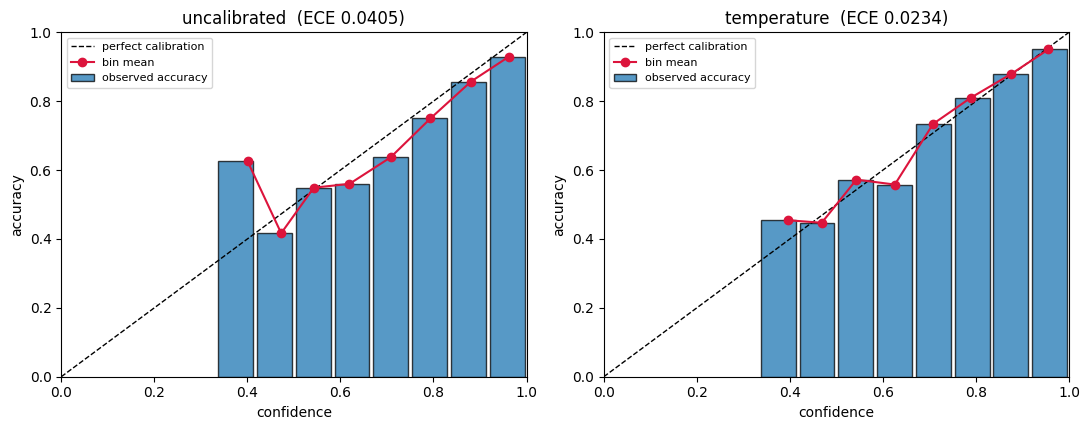

Bin detail, temperature scaled (empty bins omitted):
  confidence bin        n  mean conf   accuracy      gap
  [0.33, 0.42)          11      0.395      0.455   +0.060
  [0.42, 0.50)          85      0.468      0.447   -0.021
  [0.50, 0.58)         173      0.543      0.572   +0.029
  [0.58, 0.67)         138      0.626      0.558   -0.068
  [0.67, 0.75)         158      0.708      0.734   +0.026
  [0.75, 0.83)         142      0.789      0.810   +0.021
  [0.83, 0.92)         190      0.876      0.879   +0.003
  [0.92, 1.00)         202      0.956      0.950   -0.005


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, nm in zip(axes, ['uncalibrated', 'temperature']):
    s = calib_stats(CAL[nm], y[te], 12, False)
    edges, cnt, cs, acs, nz = s['bins']
    centres = (edges[:-1] + edges[1:]) / 2
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect calibration')
    ax.bar(centres[nz], acs[nz], width=(edges[1] - edges[0]) * 0.9, edgecolor='black',
           alpha=0.75, label='observed accuracy')
    ax.plot(cs[nz], acs[nz], 'o-', color='crimson', lw=1.5, label='bin mean')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('confidence'); ax.set_ylabel('accuracy')
    ax.set_title('%s  (ECE %.4f)' % (nm, s['ece'])); ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(ARTIFACTS_DIR, 'reliability_diagram.png'), dpi=150, bbox_inches='tight')
plt.show()

edges, cnt, cs, acs, nz = calib_stats(CAL['temperature'], y[te], 12, False)['bins']
print('Bin detail, temperature scaled (empty bins omitted):')
print('  %-16s %6s %10s %10s %8s' % ('confidence bin', 'n', 'mean conf', 'accuracy', 'gap'))
for i in range(len(cnt)):
    if cnt[i] > 0:
        print('  [%.2f, %.2f)      %6d %10.3f %10.3f %+8.3f'
              % (edges[i], edges[i + 1], cnt[i], cs[i], acs[i], acs[i] - cs[i]))


## 10. §3.5 Hybrid Explanation Layer

The methodology lists OTP request, password request, banking information, suspicious URL, urgency and
financial request — inherited from single-message SMS smishing. **Coverage on this corpus is measured
first**, because COVA-X models voice-style conversations, not SMS.

Indicators are then screened on coverage **and an effect-size floor**: at n > 10,000 a chi-square test
separates indicators on statistical power, not on anything an analyst could act on. Finally the
retained set is **faithfulness-tested** — an explanation that does not reflect what the model uses is a
mechanism for manufacturing over-reliance, which is exactly what §3.7 measures.


In [27]:
import re, collections
RX_SRC = {
 # the six from the methodology (attacker side)
 "otp_request":      (r"\b(one[- ]time (code|password|passcode)|otp|verification code|security code|"
                      r"6[- ]digit|six[- ]digit)\b", "attacker"),
 "password_request": (r"\b(password|passcode)\b", "attacker"),
 "banking_info":     (r"\b(card number|cvv|routing number|account number|social security|ssn|"
                      r"pin number|debit card|credit card)\b", "attacker"),
 "suspicious_url":   (r"(https?://|www\.|\.com/|click (the |this )?link)", "attacker"),
 "urgency":          (r"\b(immediately|right now|urgent(ly)?|act now|within the hour|"
                      r"before it'?s too late|don'?t hang up|time[- ]sensitive|last chance)\b", "attacker"),
 "financial_request":(r"\b(gift card|wire transfer|western union|moneygram|zelle|venmo|cash app|"
                      r"bitcoin|crypto|money order|prepaid card|bank transfer|payment|\$)\b", "attacker"),
 # victim-response indicators - Part I showed the detector's evidence is victim-side
 "compliance":       (r"\b(okay,? i'?ll|alright,? i'?ll|yes,? i (will|can)|let me (get|find|grab)|"
                      r"here'?s my|i'?ll do (it|that)|of course|whatever you need)\b", "victim"),
 "hesitation":       (r"\b(i'?m not sure|i don'?t know|hold on|wait a (minute|second)|let me think|"
                      r"i'?m confused|this (seems|sounds) (odd|strange|off)|not comfortable)\b", "victim"),
 "verification_seek":(r"\b(how do i know|can i (call|verify|check)|is this (real|legitimate)|"
                      r"call you back|your (badge|employee|id) number|let me (check|confirm|call))\b", "victim"),
 "distress":         (r"\b(oh (no|god|my)|i'?m (scared|worried|frightened|panicking)|what do i do|"
                      r"help me)\b", "victim"),
 "third_party":      (r"\b(my (son|daughter|husband|wife|lawyer|bank)|let me (ask|talk to|call) my|"
                      r"check with my)\b", "victim"),
}
RX   = {k: re.compile(v[0], re.I) for k, v in RX_SRC.items()}
side = {k: v[1] for k, v in RX_SRC.items()}

att_txt = [" ".join(c for r, c in d["turns"] if r == "attacker") for d in convs]
vic_txt = [" ".join(c for r, c in d["turns"] if r == "victim")   for d in convs]
HIT = {k: np.array([bool(RX[k].search((att_txt if side[k] == "attacker" else vic_txt)[i]))
                    for i in range(len(convs))]) for k in RX_SRC}

harm  = (y != 2).astype(float)          # complied or partial = some degree of compliance
FLOOR = 0.075
retained = []
print("  %-19s %-9s %8s %10s %9s %8s   verdict"
      % ("indicator", "channel", "coverage", "harm|hit", "harm|no", "|diff|"))
for k in RX_SRC:
    h = HIT[k]; cov = h.mean()
    if h.sum() < 30 or h.sum() == len(h):
        print("  %-19s %-9s %8.3f   (too rare to screen)" % (k, side[k], cov)); continue
    a_, b_ = harm[h].mean(), harm[~h].mean(); diff = abs(a_ - b_)
    ok = (0.10 <= cov <= 0.90) and diff >= FLOOR
    if ok: retained.append(k)
    print("  %-19s %-9s %8.3f %10.3f %9.3f %8.3f   %s"
          % (k, side[k], cov, a_, b_, diff, "RETAIN" if ok else "drop"))
print("\n  retained (coverage 10-90%%, |harm-rate difference| >= %.3f): %s" % (FLOOR, retained))

  indicator           channel   coverage   harm|hit   harm|no   |diff|   verdict
  otp_request         attacker     0.031      0.622     0.539    0.083   drop
  password_request    attacker     0.014      0.819     0.538    0.282   drop
  banking_info        attacker     0.307      0.478     0.570    0.092   RETAIN
  suspicious_url      attacker     0.059      0.594     0.538    0.056   drop
  urgency             attacker     0.759      0.528     0.584    0.055   drop
  financial_request   attacker     0.415      0.630     0.479    0.152   RETAIN
  compliance          victim       0.238      0.695     0.494    0.201   RETAIN
  hesitation          victim       0.347      0.473     0.578    0.106   RETAIN
  verification_seek   victim       0.202      0.443     0.567    0.124   RETAIN
  distress            victim       0.502      0.628     0.454    0.174   RETAIN
  third_party         victim       0.274      0.522     0.549    0.027   drop

  retained (coverage 10-90%, |harm-rate differen

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score

CV5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
def auroc_from(F):
    p = cross_val_predict(LogisticRegression(max_iter=2000), F, harm, cv=CV5,
                          method="predict_proba")[:, 1]
    return roc_auc_score(harm, p)

a_full = auroc_from(vec.transform(full))
a_all  = auroc_from(np.column_stack([HIT[k] for k in RX_SRC]).astype(float))
a_ret  = auroc_from(np.column_stack([HIT[k] for k in retained]).astype(float)) if retained else 0.5
BAR    = 50.0

# roc_auc_score returns a plain Python float, so a chance-level full-text model
# (AUROC exactly 0.5) made this a ZeroDivisionError rather than a NaN.
gain = a_full - 0.5
def _recovers(a):
    return 100 * (a - 0.5) / gain if gain > 1e-12 else float('nan')
frac = _recovers(a_ret)

print("=== FAITHFULNESS TEST (binary harm target, 5-fold CV) ===")
print("  %-34s AUROC %.4f   100%%" % ("full text model", a_full))
print("  %-34s AUROC %.4f   recovers %5.1f%%"
      % ("all %d indicators" % len(RX_SRC), a_all, _recovers(a_all)))
print("  %-34s AUROC %.4f   recovers %5.1f%%"
      % ("%d retained indicators" % len(retained), a_ret, frac))
print("\n  pre-declared bar for the label 'model evidence': >= %.0f%%" % BAR)
if not np.isfinite(frac):
    print("  -> UNDEFINED - the full-text model is itself at chance (AUROC %.4f), so there is"
          "\n     no above-chance discrimination for the indicators to recover." % a_full)
elif frac >= BAR:
    print("  -> PASSES - may be labelled model evidence")
else:
    print("  -> FAILS - this is CORROBORATING ANNOTATION; the interface must not")
    print("     imply it explains the score")

=== FAITHFULNESS TEST (binary harm target, 5-fold CV) ===
  full text model                    AUROC 0.9054   100%
  all 11 indicators                  AUROC 0.6882   recovers  46.4%
  6 retained indicators              AUROC 0.6711   recovers  42.2%

  pre-declared bar for the label 'model evidence': >= 50%
  -> FAILS - this is CORROBORATING ANNOTATION; the interface must not
     imply it explains the score


## 11. §3.6 Human-AI Triage Interface

All five specified elements — conversation, prediction, calibrated confidence, highlighted suspicious
turns, explanation — rendered for a real test conversation.

Two departures forced by the measurements above: the annotation is labelled **corroborating
annotation** rather than _explanation_ unless §10 earns that word, and the card shows the **scam-type
base rate** beside the estimate, because an analyst already knows the scam type and the model's
contribution is the movement from that base rate.


In [29]:
BASE_RATE = {s: harm[st == s].mean() for s in np.unique(st)}
TE_POS    = {j: i for i, j in enumerate(te)}

def _wrap(text, rxs, width=92):
    marks = sorted((m.start(), m.end(), nm) for nm, rx in rxs for m in rx.finditer(text))
    out, last, used = [], 0, []
    for s, e, nm in marks:
        if s < last: continue
        out += [text[last:s], ">>" + text[s:e] + "<<"]; used.append(nm); last = e
    out.append(text[last:])
    lines, cur = [], ""
    for w in "".join(out).split():
        if len(cur) + len(w) + 1 > width: lines.append(cur); cur = w
        else: cur = (cur + " " + w).strip()
    if cur: lines.append(cur)
    return lines, sorted(set(used))

def triage_card(j, probs, max_turns=8, tau=0.90):
    d = convs[j]; p = probs[TE_POS[j]]
    pred = int(p.argmax()); conf = float(p.max())
    br = BASE_RATE[d["scam_type"]]; p_harm = float(p[0] + p[1])
    print("=" * 96)
    print("TRIAGE CARD   %s" % d["cid"]); print("=" * 96)
    print("  scam type          : %s" % d["scam_type"])
    print("  PREDICTION         : %s" % NAMES[pred].upper())
    print("  calibrated conf.   : %.1f%%   (temperature-scaled, T = %.3f)" % (100*conf, T))
    print("  P(some compliance) : %.1f%%" % (100*p_harm))
    print("  scam-type base rate: %.1f%%   -> model moves the estimate %+.1f points"
          % (100*br, 100*(p_harm - br)))
    print("  selective triage   : %s (confidence %s tau=%.2f)"
          % ("AUTO-TRIAGE" if conf >= tau else "ROUTE TO ANALYST", ">=" if conf >= tau else "<", tau))
    print("-" * 96)
    print("  CONVERSATION  (first %d turns; >>...<< marks a corroborating annotation)" % max_turns)
    arx = [(k, RX[k]) for k in RX_SRC if side[k] == "attacker"]
    vrx = [(k, RX[k]) for k in RX_SRC if side[k] == "victim"]
    fa, fv = set(), set()
    for role, content in d["turns"][:max_turns]:
        lines, used = _wrap(content, arx if role == "attacker" else vrx)
        (fa if role == "attacker" else fv).update(used)
        print("  [%-8s] %s" % (role.upper(), lines[0] if lines else ""))
        for ex in lines[1:]: print("  %-11s %s" % ("", ex))
    print("-" * 96)
    print("  CORROBORATING ANNOTATION  (context only - NOT an explanation of the score)")
    print("    attacker tactics : %s" % (", ".join(sorted(fa)) or "none in these turns"))
    print("    victim responses : %s" % (", ".join(sorted(fv)) or "none in these turns"))
    print("    faithfulness     : retained indicators recover %.1f%% of the model's above-chance" % frac)
    print("                       discrimination%s" %
          ("" if frac >= BAR else " - below the %.0f%% bar, so they do NOT explain the score" % BAR))
    print("=" * 96)

# Prefer a bank conversation, but never index an empty list: fall back to any test item.
demo_pool = [j for j in te if convs[j]["scam_type"] == "bank"] or list(te)
triage_card(demo_pool[0], CAL["temperature"])

TRIAGE CARD   bank_20260329_074432_8555
  scam type          : bank
  PREDICTION         : REJECTED
  calibrated conf.   : 68.3%   (temperature-scaled, T = 1.208)
  P(some compliance) : 31.7%
  scam-type base rate: 40.4%   -> model moves the estimate -8.8 points
  selective triage   : ROUTE TO ANALYST (confidence < tau=0.90)
------------------------------------------------------------------------------------------------
  CONVERSATION  (first 8 turns; >>...<< marks a corroborating annotation)
  [VICTIM  ] This is William, who's this?
  [ATTACKER] Good afternoon, William, this is Michael Stevens from Chase Bank's Fraud Department,
              Employee ID EMP-7742. I'm calling regarding some suspicious activity we've detected on your
              account ending in 1234. Can you confirm that you were the one making these transactions?
  [VICTIM  ] >>Oh no<<, is my account really under threat? These aren't my transactions at all. What do I
              need to do to secure it? Can you 

## 12. §3.7 Human Evaluation — instrument

A notebook cannot run a human study; it can build and verify the instrument so nothing is discovered
mid-recruitment.

**Four conditions, not three.** The methodology lists Human only / + raw AI / + calibrated AI. Part I
showed an analyst already knows the scam type, so without a **Human + scam-type base rate** control the
study cannot separate "calibrated confidence helped" from "knowing the scam type helped". Arm 3 vs
arm 4 is the comparison that carries the claim.

**Gate.** The full study is not fielded until a pilot shows humans meaningfully above chance and below
ceiling — near chance, "appropriate reliance" has no referent.


In [30]:
import pandas as pd, hashlib

def build_stimulus_set(n=40, n_turns=6, seed=SEED):
    rng = np.random.default_rng(seed)
    by = collections.defaultdict(list)
    for j in te: by[(convs[j]["scam_type"], y[j])].append(j)
    keys, picks = sorted(by), []
    while len(picks) < n and any(by[k] for k in keys):
        for k in keys:
            if by[k] and len(picks) < n:
                picks.append(by[k].pop(rng.integers(len(by[k]))))
    rows = []
    for j in picks:
        d = convs[j]
        key = str(d["cid"]) if d.get("cid") else "conv-%d" % j     # cid is optional in the schema
        rows.append({"item_id": hashlib.md5(key.encode()).hexdigest()[:10],
                     "cid": key, "scam_type": d["scam_type"],
                     "prefix": "\n".join("%s: %s" % (r.upper(), c) for r, c in d["turns"][:n_turns]),
                     "true_label": NAMES[y[j]], "true_harm": int(y[j] != 2),
                     "base_rate": round(float(BASE_RATE[d["scam_type"]]), 4)})
    return pd.DataFrame(rows)

STIM = build_stimulus_set()
STIM.to_csv(os.path.join(ARTIFACTS_DIR, "pilot_stimuli.csv"), index=False)
print("stimulus set: %d items | %d scam types | harm base rate %.3f"
      % (len(STIM), STIM.scam_type.nunique(), STIM.true_harm.mean()))
print(STIM.groupby(["scam_type", "true_label"]).size().unstack(fill_value=0))
print("\nresponse schema (one row per participant x item):")
for f, desc in [("participant_id","anonymous id"),
                ("condition","1=human only | 2=+raw AI | 3=+calibrated AI+annotation | 4=+base rate"),
                ("item_id","join key to the stimulus set"),
                ("judgement","complied / partial / rejected"),
                ("confidence","0-100 slider - REQUIRED; a binary judgement makes human calibration incomputable"),
                ("decision_ms","time to decision"),
                ("followed_ai","did the judgement match the AI suggestion (arms 2-4)"),
                ("nasa_tlx_*","6 subscales, once per condition")]:
    print("  %-16s %s" % (f, desc))
print("\nwrote pilot_stimuli.csv to ARTIFACTS_DIR")

stimulus set: 40 items | 8 scam types | harm base rate 0.675
true_label                complied  partial  rejected
scam_type                                            
bank                             2        2         2
government_impersonation         2        2         2
grandparent                      2        2         2
investment                       2        2         2
lottery                          2        2         2
medicare                         2        1         1
romance                          1        1         1
virtual_kidnapping               1        1         1

response schema (one row per participant x item):
  participant_id   anonymous id
  condition        1=human only | 2=+raw AI | 3=+calibrated AI+annotation | 4=+base rate
  item_id          join key to the stimulus set
  judgement        complied / partial / rejected
  confidence       0-100 slider - REQUIRED; a binary judgement makes human calibration incomputable
  decision_ms      time to dec

In [31]:
def analyse_pilot(resp, stim):
    m = resp.merge(stim[["item_id", "true_harm"]], on="item_id")
    m["human_harm"] = (m.judgement != "rejected").astype(int)
    m["p_harm"] = np.where(m.human_harm == 1, m.confidence/100.0, 1 - m.confidence/100.0)
    print("  %-10s %8s %10s %10s %12s" % ("condition", "n", "accuracy", "AUROC", "median ms"))
    out = {}
    for c, g in m.groupby("condition"):
        acc = (g.human_harm == g.true_harm).mean()
        au  = roc_auc_score(g.true_harm, g.p_harm) if g.true_harm.nunique() > 1 else float("nan")
        out[c] = (acc, au)
        print("  %-10s %8d %10.4f %10.4f %12.0f" % (c, len(g), acc, au, g.decision_ms.median()))
    a1 = out.get(1, (np.nan, np.nan))[1]
    ok = 0.60 < a1 < 0.95
    print("\n  GATE: human-only AUROC %.4f -> %s" % (a1, "PASS" if ok else "FAIL"))
    if not ok:
        print("    'appropriate reliance' has no referent; revisit the design before recruiting.")
    a3, a4 = out.get(3, (np.nan,))[0], out.get(4, (np.nan,))[0]
    print("\n  THE COMPARISON THAT CARRIES THE CLAIM")
    print("    arm 3 (calibrated AI) %.4f  vs  arm 4 (base rate only) %.4f  ->  %+.4f"
          % (a3, a4, a3 - a4))
    print("    if ~0, calibrated confidence adds nothing beyond knowing the scam type.")
    print("\n  HUMAN CALIBRATION vs MODEL")
    for c, g in m.groupby("condition"):
        pr = np.column_stack([1 - g.p_harm, g.p_harm])
        print("    condition %s: human aECE %.4f"
              % (c, calib_stats(pr, g.true_harm.values, 8, True)["ece"]))
    mp = CAL["temperature"]
    mh = np.column_stack([mp[:, 2], mp[:, 0] + mp[:, 1]])
    print("    model      : aECE %.4f (binary harm, temperature-scaled)"
          % calib_stats(mh, (y[te] != 2).astype(int), 8, True)["ece"])
    return out

rng = np.random.default_rng(SEED); sim = []
for pid in range(12):
    cond = (pid % 4) + 1
    skill = {1: 0.62, 2: 0.68, 3: 0.74, 4: 0.70}[cond]
    for _, r in STIM.iterrows():
        ok_ = rng.random() < skill
        hh = r.true_harm if ok_ else 1 - r.true_harm
        sim.append({"participant_id": pid, "condition": cond, "item_id": r.item_id,
                    "judgement": "partial" if hh else "rejected",
                    "confidence": float(np.clip(rng.normal(72 if ok_ else 60, 14), 50, 99)),
                    "decision_ms": float(rng.lognormal(9.4, 0.4))})
SIM = pd.DataFrame(sim)
print("SIMULATED pilot (%d participants x %d items) - verifies the pipeline, NOT a result\n"
      % (SIM.participant_id.nunique(), len(STIM)))
_ = analyse_pilot(SIM, STIM)

SIMULATED pilot (12 participants x 40 items) - verifies the pipeline, NOT a result

  condition         n   accuracy      AUROC    median ms
  1               120     0.5917     0.7034        12221
  2               120     0.7167     0.8512        10881
  3               120     0.7917     0.8677        12239
  4               120     0.6500     0.7556        13048

  GATE: human-only AUROC 0.7034 -> PASS

  THE COMPARISON THAT CARRIES THE CLAIM
    arm 3 (calibrated AI) 0.7917  vs  arm 4 (base rate only) 0.6500  ->  +0.1417
    if ~0, calibrated confidence adds nothing beyond knowing the scam type.

  HUMAN CALIBRATION vs MODEL
    condition 1: human aECE 0.1077
    condition 2: human aECE 0.1229
    condition 3: human aECE 0.1028
    condition 4: human aECE 0.0862
    model      : aECE 0.0222 (binary harm, temperature-scaled)


## 13. §3.8 Statistical Analysis

Repeated-measures ANOVA across conditions where its assumptions hold, non-parametric equivalent
otherwise, with Holm-corrected pairwise follow-ups against the base-rate control. Calibration
differences use a **paired** bootstrap on shared predictions.


In [32]:
from scipy import stats

def condition_tests(resp, stim):
    m = resp.merge(stim[["item_id", "true_harm"]], on="item_id")
    m["correct"] = ((m.judgement != "rejected").astype(int) == m.true_harm).astype(int)
    per = m.groupby(["participant_id", "condition"]).correct.mean().reset_index()
    conds = sorted(per.condition.unique())
    groups = [per[per.condition == c].correct.values for c in conds]
    print("  mean accuracy:", "  ".join("c%d %.3f" % (c, g.mean()) for c, g in zip(conds, groups)))

    # Shapiro-Wilk needs n>=3 and an omnibus test needs >=2 groups. A small pilot can
    # supply neither; say so instead of raising.
    resid = np.concatenate([g - g.mean() for g in groups]) if groups else np.array([])
    if resid.size >= 3:
        W, p_norm = stats.shapiro(resid)
        print("  Shapiro-Wilk on pooled residuals: W=%.3f p=%.4f -> %s"
              % (W, p_norm, "normality tenable" if p_norm > .05 else "normality rejected"))
    else:
        p_norm = 0.0
        print("  Shapiro-Wilk skipped: only %d residuals - defaulting to the "
              "non-parametric test" % resid.size)

    if len(groups) < 2:
        print("  omnibus test skipped: only %d condition present" % len(groups))
    elif p_norm > .05:
        F, p = stats.f_oneway(*groups); print("  one-way ANOVA  : F=%.3f p=%.4f" % (F, p))
    else:
        H, p = stats.kruskal(*groups);  print("  Kruskal-Wallis : H=%.3f p=%.4f" % (H, p))
    print("  (between-subjects here because the simulation gives each participant one condition;")
    print("   a within-subjects design uses repeated-measures ANOVA / Friedman.)")
    print("\n  pairwise vs arm 4 (base-rate control), Holm-corrected:")
    ref = per[per.condition == 4].correct.values
    if ref.size == 0:
        print("    arm 4 (base-rate control) is absent - no comparison to make.")
        return
    raw = [(c, *stats.ttest_ind(per[per.condition == c].correct.values, ref))
           for c in conds if c != 4]
    if not raw:
        print("    no other arms to compare against arm 4.")
        return
    order = np.argsort([r[2] for r in raw]); mm = len(raw); adj = {}; run = 0.0
    for rank, oi in enumerate(order):
        run = max(run, raw[oi][2] * (mm - rank)); adj[raw[oi][0]] = min(1.0, run)
    for c, t, pp in raw:
        print("    arm %d vs 4 : t=%+.3f  p=%.4f  p_holm=%.4f  %s"
              % (c, t, pp, adj[c], "*" if adj[c] < .05 else "n.s."))

def paired_bootstrap_ece(pa, pb, y_true, B=400, seed=SEED):
    rng = np.random.default_rng(seed); n = len(y_true); d = np.empty(B)
    for i in range(B):
        ix = rng.integers(0, n, n)
        d[i] = (calib_stats(pa[ix], y_true[ix], 15, True)["ece"]
                - calib_stats(pb[ix], y_true[ix], 15, True)["ece"])
    return d.mean(), *np.percentile(d, [2.5, 97.5])

condition_tests(SIM, STIM)
print("\n  calibration: temperature vs uncalibrated, paired bootstrap on shared test predictions")
mn, lo, hi = paired_bootstrap_ece(CAL["temperature"], CAL["uncalibrated"], y[te])
print("    delta aECE = %+.4f   95%% CI [%+.4f, %+.4f]   %s"
      % (mn, lo, hi, "excludes 0" if (lo > 0 or hi < 0) else "includes 0"))
print("    (negative = temperature scaling reduces calibration error)")
print("\n  multiplicity, as pre-registered:")
print("    H1a/H1b co-primaries : uncorrected, alpha=0.05")
print("    calibration methods  : Holm-Bonferroni, FWER 0.05")
print("    subgroups / horizons : Benjamini-Hochberg, q=0.05")

  mean accuracy: c1 0.592  c2 0.717  c3 0.792  c4 0.650
  Shapiro-Wilk on pooled residuals: W=0.908 p=0.1991 -> normality tenable
  one-way ANOVA  : F=14.267 p=0.0014
  (between-subjects here because the simulation gives each participant one condition;
   a within-subjects design uses repeated-measures ANOVA / Friedman.)

  pairwise vs arm 4 (base-rate control), Holm-corrected:
    arm 1 vs 4 : t=-1.750  p=0.1550  p_holm=0.2322  n.s.
    arm 2 vs 4 : t=+2.000  p=0.1161  p_holm=0.2322  n.s.
    arm 3 vs 4 : t=+8.500  p=0.0011  p_holm=0.0032  *

  calibration: temperature vs uncalibrated, paired bootstrap on shared test predictions
    delta aECE = -0.0077   95% CI [-0.0271, +0.0125]   includes 0
    (negative = temperature scaling reduces calibration error)

  multiplicity, as pre-registered:
    H1a/H1b co-primaries : uncorrected, alpha=0.05
    calibration methods  : Holm-Bonferroni, FWER 0.05
    subgroups / horizons : Benjamini-Hochberg, q=0.05


---

### What Part II establishes

**Real data:** temperature and vector scaling with reliability diagrams (§9); indicator screening and
the faithfulness test (§10); the analyst card on a real test conversation (§11).

**Instrument only:** §12 verifies the human-study apparatus against _simulated_ responses. Those
numbers say nothing about human performance — they prove the stimulus set, schema and analysis compose.

**Not run here:** the confirmatory evaluation, which uses the thesis's 60/15/25 split and the
pre-registered hypotheses, with the test partition closed until the detector sweep completes.

**The checks that can fail are the point.** §9 asserts accuracy is unchanged by temperature scaling.
§10 refuses the label _model evidence_ below 50% recovered discrimination. §12's gate refuses to field
the study if humans sit near chance.


## 14. Package outputs for download

Zips everything in `ARTIFACTS_DIR` into `/kaggle/working/covax_output.zip` for one-click
download from the Kaggle **Output** tab.

**Expected contents**

| File                       | Description                                | Approx. size |
| -------------------------- | ------------------------------------------ | ------------ |
| `covax_cache.pkl`          | Parsed corpus (10,985 conversations)       | ~70 MB       |
| `reliability_diagram.png`  | Section 9.1 calibration figure             | ~200 KB      |
| `pilot_stimuli.csv`        | Human-eval stimulus set (40 items)         | ~100 KB      |
| `distilbert_tail_best.pt`  | Best DistilBERT checkpoint (if section 7 ran) | ~270 MB   |
| `longformer_best.pt`       | Best Longformer checkpoint (if section 7 ran) | ~600 MB   |

Set `INCLUDE_CHECKPOINTS = False` below to zip only the small artifacts.


In [33]:
import zipfile, os, glob

ZIP_OUT             = os.path.join(WORK_DIR, 'covax_output.zip')
INCLUDE_CHECKPOINTS = True     # False -> skip the .pt files (much smaller download)

files = sorted(f for f in glob.glob(os.path.join(ARTIFACTS_DIR, '**', '*'), recursive=True)
               if os.path.isfile(f))
if not INCLUDE_CHECKPOINTS:
    files = [f for f in files if not f.endswith('.pt')]

if not files:
    print('nothing to package - %s is empty' % ARTIFACTS_DIR)
else:
    print('Zipping %d files from %s ...' % (len(files), ARTIFACTS_DIR))
    total_raw = 0
    with zipfile.ZipFile(ZIP_OUT, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
        for fpath in files:
            arcname = os.path.relpath(fpath, ARTIFACTS_DIR)
            sz = os.path.getsize(fpath)
            total_raw += sz
            print('  %-40s %8.1f MB' % (arcname, sz / 1024**2), flush=True)
            zf.write(fpath, arcname)

    zip_sz = os.path.getsize(ZIP_OUT)
    print('\nDone.')
    print('  Raw total : %.1f MB' % (total_raw / 1024**2))
    print('  Zip file  : %.1f MB  (%.0f%% of original)'
          % (zip_sz / 1024**2, 100 * zip_sz / total_raw if total_raw else 0))
    print('  Location  : %s' % ZIP_OUT)
    print('\nDownload from the Kaggle Output tab (right panel).')


Zipping 5 files from /kaggle/working/covax_artifacts ...
  covax_cache.pkl                              70.3 MB
  distilbert_tail_best.pt                     255.5 MB
  longformer_best.pt                          567.2 MB
  pilot_stimuli.csv                             0.1 MB
  reliability_diagram.png                       0.1 MB

Done.
  Raw total : 893.1 MB
  Zip file  : 750.7 MB  (84% of original)
  Location  : /kaggle/working/covax_output.zip

Download from the Kaggle Output tab (right panel).
